<h1 style="font-family:'Times New Roman';font-size:45px;"><font color='purple'><center>~ Natural Language Processing: Stock Market News Sentiment Analysis and Summarization Project ~ </center></font></h1><br><br>

<i><p style="font-family:'Times New Roman';font-size:30px;"><font color='purple'><b>Project by: Punnya Bhatnagar</b></font></p></i><br>
<i><p style="font-family:'Times New Roman';font-size:28px;"><font color='purple'><b>Batch: AIML Online April 2024 A</b></font></p></i><br><br>

<center><img src="https://images.pexels.com/photos/159888/pexels-photo-159888.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=1" width="650"></center>

<br><br><h1 style="font-family:'Times New Roman';"><font color='navy'> Context</font></h1>

<p style="font-family:'Georgia';font-size:15px;">The prices of the stocks of companies listed under a global exchange are influenced by a variety of factors, with the company's financial performance, innovations and collaborations, and market sentiment being factors that play a significant role. News and media reports can rapidly affect investor perceptions and, consequently, stock prices in the highly competitive financial industry.<br> With the sheer volume of news and opinions from a wide variety of sources, investors and financial analysts often struggle to stay updated and accurately interpret its impact on the market. As a result, investment firms need sophisticated tools to analyze market sentiment and integrate this information into their investment strategies.

<h1 style="font-family:'Times New Roman';"><font color='navy'> Problem Definition </font></h1>

<p style="font-family:'Georgia';font-size:15px;">With an ever-rising number of news articles and opinions, an investment startup aims to leverage artificial intelligence to address the challenge of interpreting stock-related news and its impact on stock prices. They have collected historical daily news for a specific company listed under NASDAQ, along with data on its daily stock price and trade volumes.<br><br>As a member of the Data Science and AI team in the startup, you have been tasked with analyzing the data, developing an AI-driven sentiment analysis system that will automatically process and analyze news articles to gauge market sentiment, and summarizing the news at a weekly level to enhance the accuracy of their stock price predictions and optimize investment strategies. This will empower their financial analysts with actionable insights, leading to more informed investment decisions and improved client outcomes.

<h1 style="font-family:'Times New Roman';"><font color='navy'> Data Dictionary </font></h1>

<p style="font-family:'Georgia';font-size:15px;">
1.   Date: The date the news was released<br>
2.   News: The content of news articles that could potentially affect the company's stock price<br>
3. Open: The stock price (in \$) at the beginning of the day <br>
4. High: The highest stock price (in \$) reached during the day<br>
5. Low: The lowest stock price (in \$) reached during the day<br>
6. Close: The adjusted stock price (in $) at the end of the day<br>
7. Volume: The number of shares traded during the day<br>
8. Label: The sentiment polarity of the news content<br>
    <li>1: Positive
    <li>0: Neutral
    <li>-1: Negative</p>

<h1 style="font-family:'Times New Roman';"><font color='navy'> 1. Exploratory Data Analysis </font></h1>

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>1.1 Univariate analysis</b></font></h3>

<b>Importing necessary libraries

In [2]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# installing the sentence-transformers and gensim libraries for word embeddings
!pip install -U sentence-transformers gensim transformers tqdm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 31.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 60.3 MB/s eta 0:00:00


<b>Reading ‘stock_news.csv’ as a DataFrame and assigning it
to a variable.

In [ ]:
stock_df = pd.read_csv('/content/drive/MyDrive/nlp/stock_news.csv')

In [8]:
stock_df.head() #first 5 records

,Date,News,Open,High,Low,Close,Volume,Label
0,2019-01-02,The tech sector experienced a significant dec...,41.740002,42.244999,41.482498,40.246914,130672400,-1
1,2019-01-02,Apple lowered its fiscal Q1 revenue guidance ...,41.740002,42.244999,41.482498,40.246914,130672400,-1
2,2019-01-02,Apple cut its fiscal first quarter revenue fo...,41.740002,42.244999,41.482498,40.246914,130672400,-1
3,2019-01-02,This news article reports that yields on long...,41.740002,42.244999,41.482498,40.246914,130672400,-1
4,2019-01-02,Apple's revenue warning led to a decline in U...,41.740002,42.244999,41.482498,40.246914,130672400,-1


<b>Checking shape of the dataframe.

In [9]:
print("There are", stock_df.shape[0], 'rows and', stock_df.shape[1], "columns.")

There are 349 rows and 8 columns.


<b>Checking the data types of columns along with the non null
counts.

In [10]:
stock_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349 entries, 0 to 348
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    349 non-null    object 
 1   News    349 non-null    object 
 2   Open    349 non-null    float64
 3   High    349 non-null    float64
 4   Low     349 non-null    float64
 5   Close   349 non-null    float64
 6   Volume  349 non-null    int64  
 7   Label   349 non-null    int64  
dtypes: float64(4), int64(2), object(2)
memory usage: 21.9+ KB


<b>Checking for missing values

In [11]:
# Checking for missing values
stock_df.isnull().sum()

,0
Date,0
News,0
Open,0
High,0
Low,0
Close,0
Volume,0
Label,0


<i>There are no missing values.

<b>Checking for duplicate entries

In [12]:
stock_df.duplicated().sum()

0

<i>The above shows that there are no duplicate entries in the data.

<b>Changing Label type to 'category' as it is the news sentiment. (for EDA purpose)

In [13]:
stock_df.Label = stock_df.Label.astype('object')

<b>Changing Date type to 'datetime'.

In [14]:
stock_df.Date = pd.to_datetime(stock_df['Date'])

<b>Printing 5 point summary of the numerical features.

In [15]:
stock_df.describe() # numerical columns 5 point summary

,Date,Open,High,Low,Close,Volume
count,349,349.000000,349.000000,349.000000,349.000000,3.490000e+02
mean,2019-02-16 16:05:30.085959936,46.229233,46.700458,45.745394,44.926317,1.289482e+08
min,2019-01-02 00:00:00,37.567501,37.817501,37.305000,36.254131,4.544800e+07
25%,2019-01-14 00:00:00,41.740002,42.244999,41.482498,40.246914,1.032720e+08
50%,2019-02-05 00:00:00,45.974998,46.025002,45.639999,44.596924,1.156272e+08
75%,2019-03-22 00:00:00,50.707500,50.849998,49.777500,49.110790,1.511252e+08
max,2019-04-30 00:00:00,66.817497,67.062500,65.862503,64.805229,2.444392e+08
std,NaN,6.442817,6.507321,6.391976,6.398338,4.317031e+07


<b>Printing summary of the categorical features.

In [16]:
stock_df.describe(include='O')

,News,Label
count,349,349
unique,349,3
top,"In the first quarter, South Korea's Samsung E...",0
freq,1,170


<b>Distribution of Numerical Columns

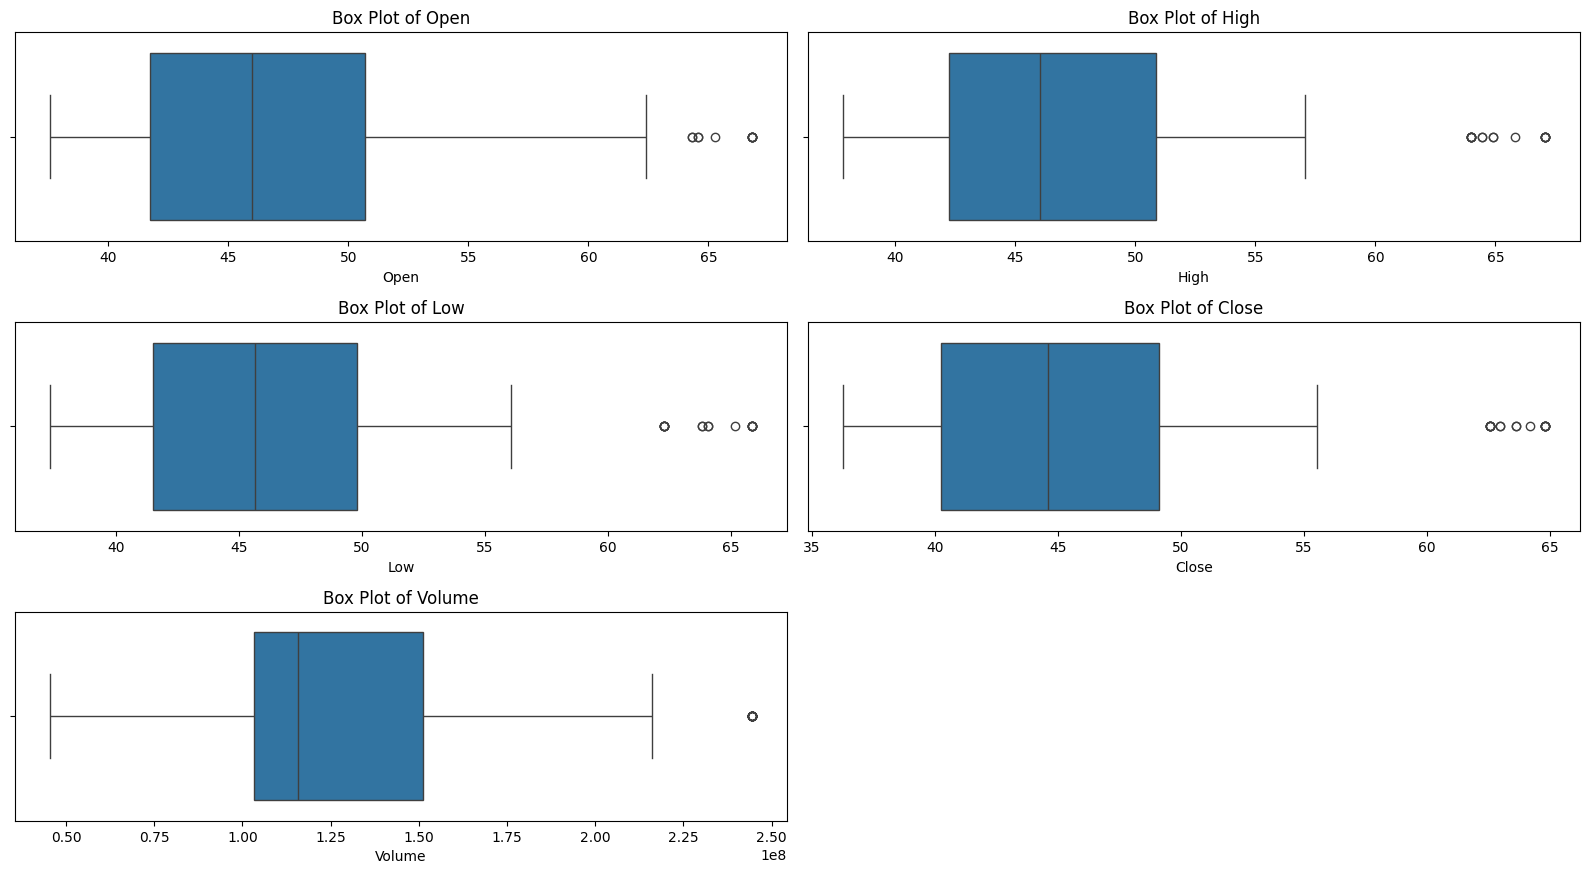

In [17]:
#Box plots :
cols_n = ['Open', 'High', 'Low', 'Close', 'Volume']

# Creating subplots
fig, axes = plt.subplots(7, 2, figsize=(16, 20))

# Flattening the axes array for iteration
axes = axes.flatten()

# Generating the box plots
for i, column in enumerate(cols_n):
  sns.boxplot(data=stock_df, x=column, ax=axes[i])
  axes[i].set_title(f'Box Plot of {column}')
# Removing the extra subplot
for j in range(len(cols_n), len(axes)):
  fig.delaxes(axes[j])

# Adjusting layout
plt.tight_layout()
plt.show()

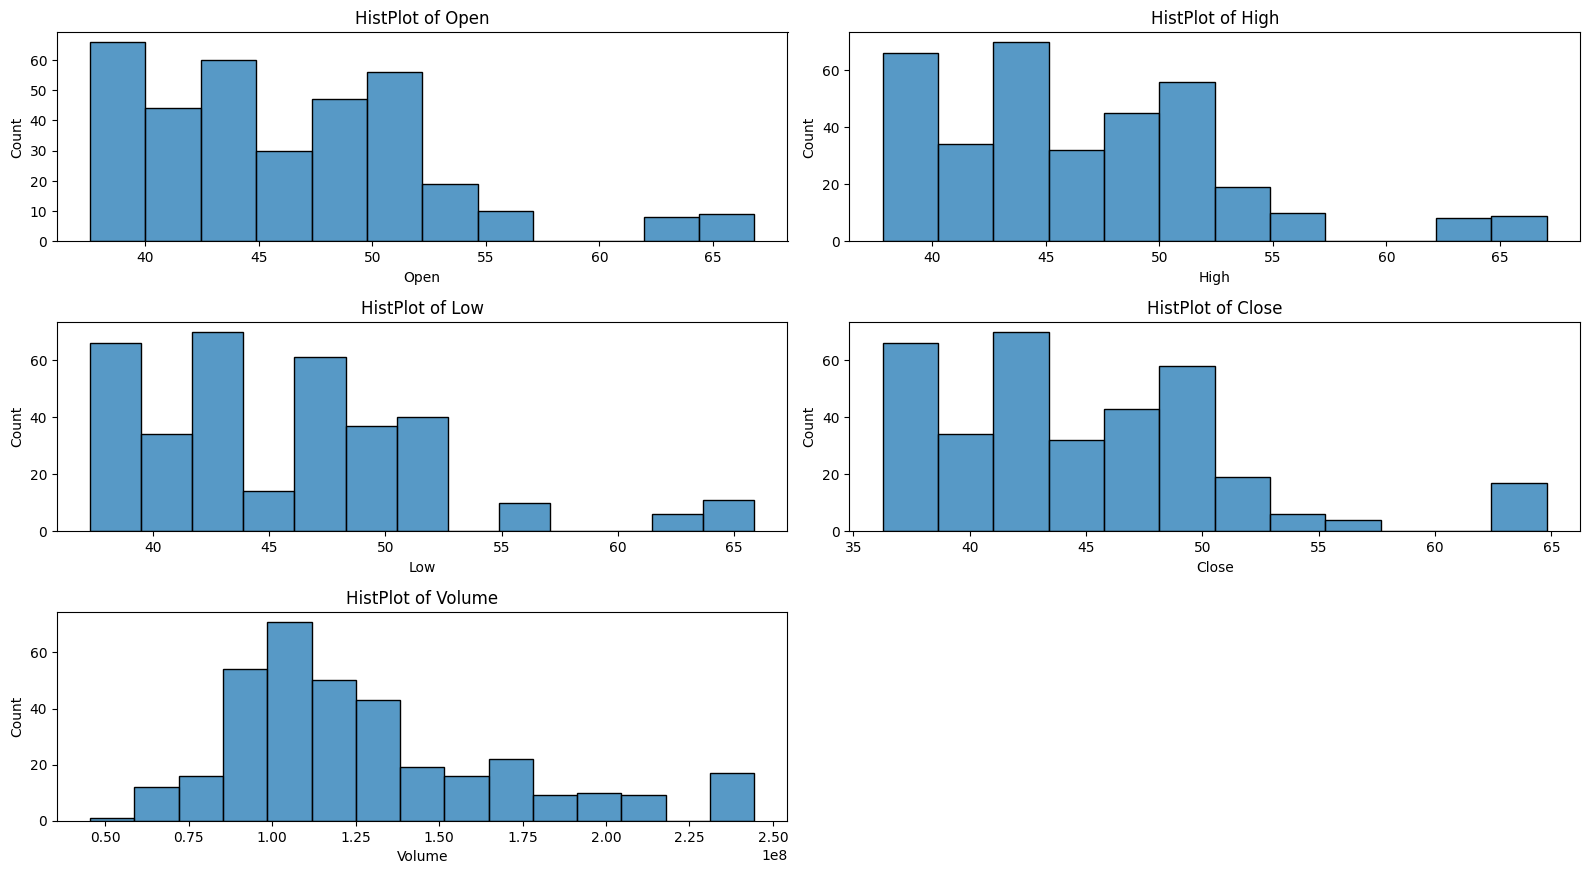

In [18]:
#Hist plots :
# Creating subplots
fig, axes = plt.subplots(7, 2, figsize=(16, 20))

# Flattening the axes array for iteration
axes = axes.flatten()

# Generating the box plots
for i, column in enumerate(cols_n):
  sns.histplot(data=stock_df, x=column, ax=axes[i])
  axes[i].set_title(f'HistPlot of {column}')

# Removing the extra subplot
for j in range(len(cols_n), len(axes)):
  fig.delaxes(axes[j])

# Adjusting layout
plt.tight_layout()
plt.show()

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br></p>

<b>Open:</b> On average, the stock prices (in $) at the beginning of the day are 46. Maximum and minimum opening values are 66.8 and 37.5 respectiely. There are outliers.<br>

<b>High:</b> On average, the highest stock prices (in $) reached during the day are 46.7. Maximum and minimum high values are 37.8 and 67 respectiely. There are outliers.<br>

<b>Low:</b> On average, the lowest stock prices (in $) reached during the day are 45.7. Maximum and minimum low values are 65.8 and 37 respectiely. There are outliers.<br>

<b>Close:</b> On average, the stock prices (in $) at the end of the day are 44.9. Maximum and minimum closing values are 64.8 and 36.2 respectiely. There are outliers.<br>

<b>Volume:</b> On average, the number of shares traded during the day are 128,948,200. Maximum and minimum volume values are 244,439,200 and 45,448,000 respectiely. There are outliers.<br>


<b>Distribution of Categorical Columns

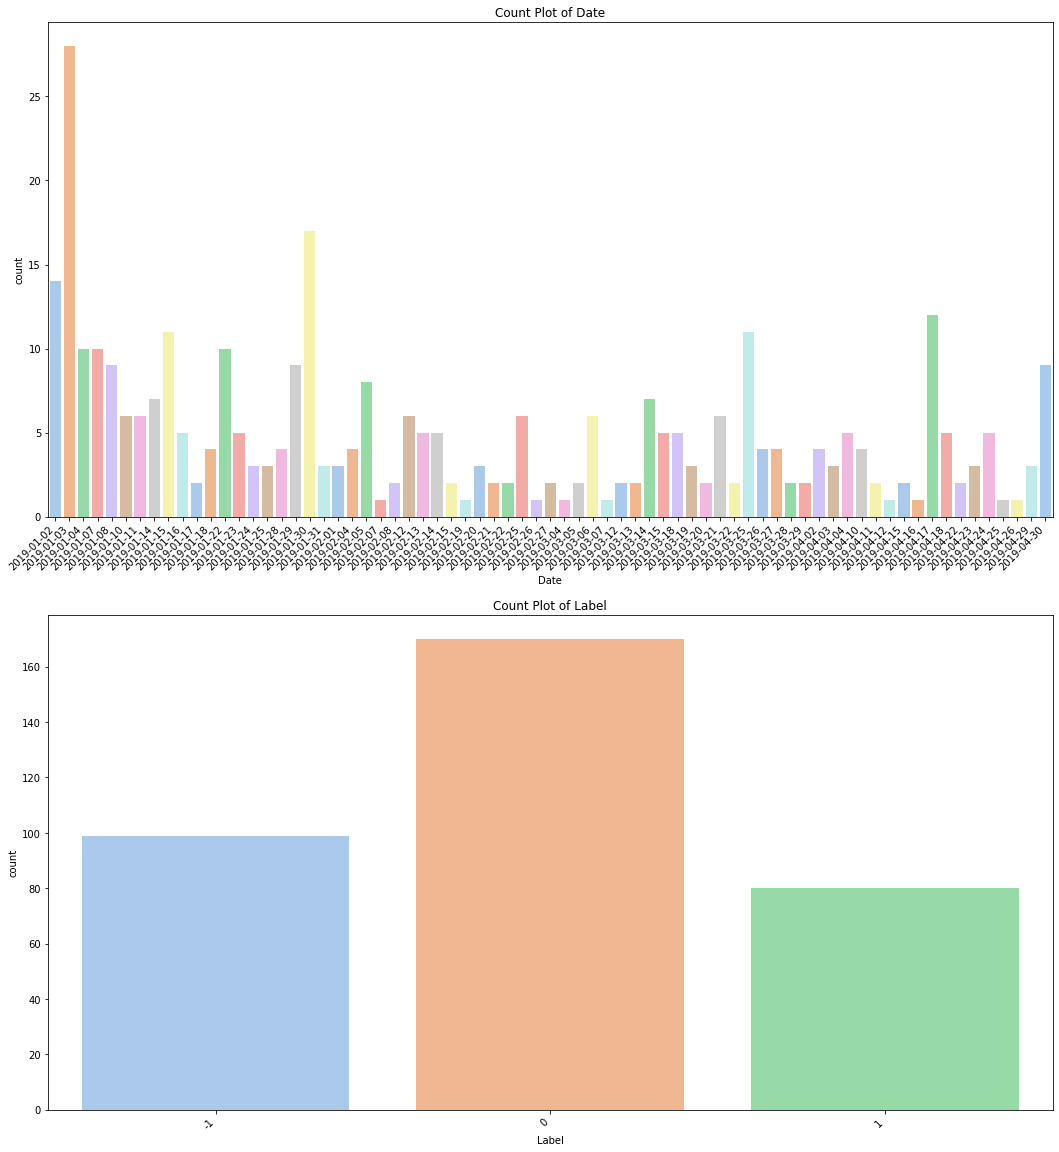

In [4]:
#Count plots
cols = ['Date', 'Label']

# Creating subplots
fig, axes = plt.subplots(2,1 , figsize=(18, 20))

# Flattening the axes array for iteration
axes = axes.flatten()

# Generating the count plots
for i, column in enumerate(cols):
  sns.countplot(data=stock_df, x=column, ax=axes[i], palette ='pastel');
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha='right')
  axes[i].set_title(f'Count Plot of {column}');

In [20]:
stock_df.Label.value_counts() #counting exact number of news belonging to each sentiment category.

,count
Label,
0,170
-1,99
1,80


<br><b>For 'News' column ,I will be using a word cloud which is a visual representation of text data where the size of each word indicates its frequency or importance in a given dataset. It is used in Natural Language Processing (NLP) for summarizing large text, identifying key themes, and gaining quick insights into dominant topics.

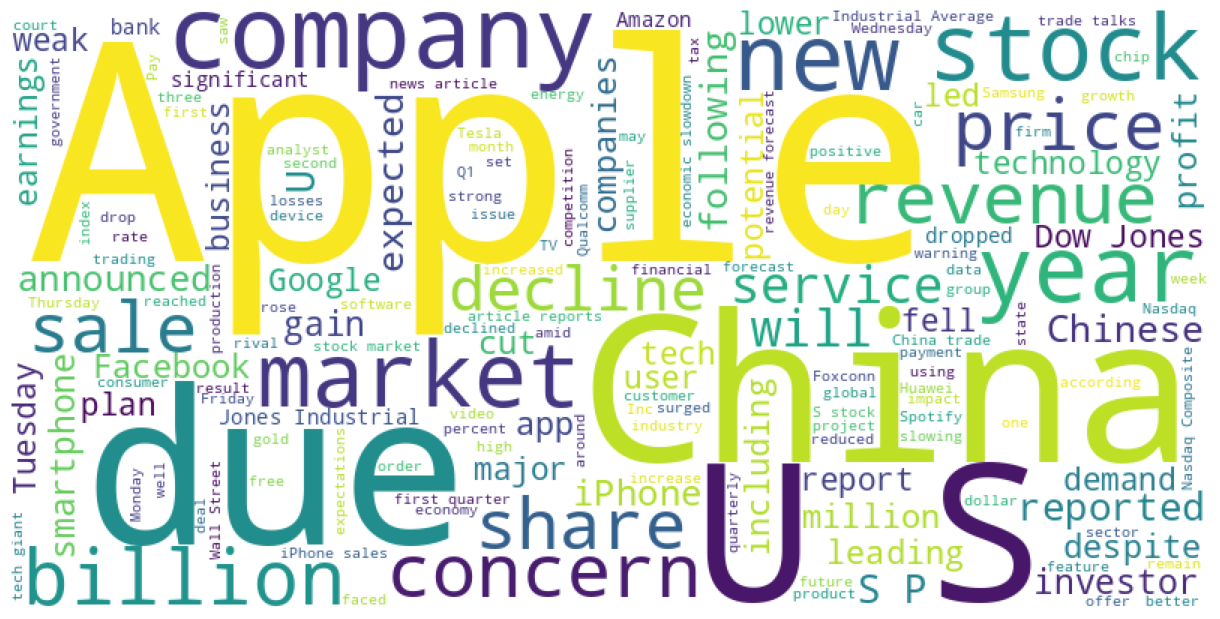

In [21]:
from wordcloud import WordCloud, STOPWORDS

# Combininig all news articles into a single string
all_news_text = ' '.join(stock_df['News'].astype(str).tolist())

# Creating a WordCloud object
wordcloud = WordCloud(width=800, height=400,
                      background_color='white',
                      stopwords=STOPWORDS,
                      min_font_size=10).generate(all_news_text)

# Displaying the generated image
plt.figure(figsize=(12, 12), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>
    
<b>Date:</b> Total of 349 news were released. Maximum number of news were released on '2019-01-03'.<br>

<b>Label:</b> Maximum news were 'Neutral' (170) followed by 'Negative'(99) then 'Positive'(80).<br>

<b>News:</b> The largest words, such as "Apple," "China," "company," "market," "stock," and "decline," indicate the most frequently mentioned topics in the dataset. <br>Words like "concern," "decline," "lower," and "fell" suggest a focus on potential negative sentiment, possibly related to financial losses or market instability.<br> Terms like "price," "earnings," "gain," "drop," "Nasdaq," and "Dow Jones" indicate a strong focus on stock movements and investor reactions.<br>



<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>1.2 Bivariate analysis</b></font></h3>

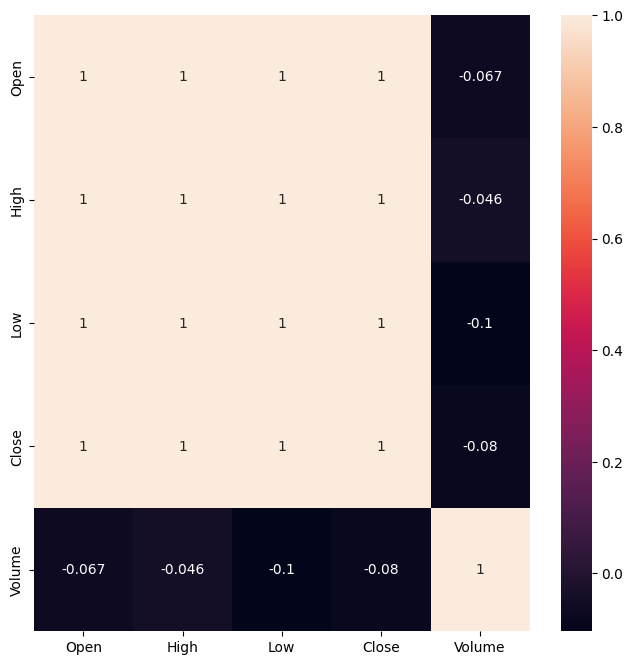

In [22]:
#Heatmap
numeric_df = stock_df.select_dtypes(include=np.number)
plt.figure(figsize=(8,8))
sns.heatmap(numeric_df.corr(),annot=True);

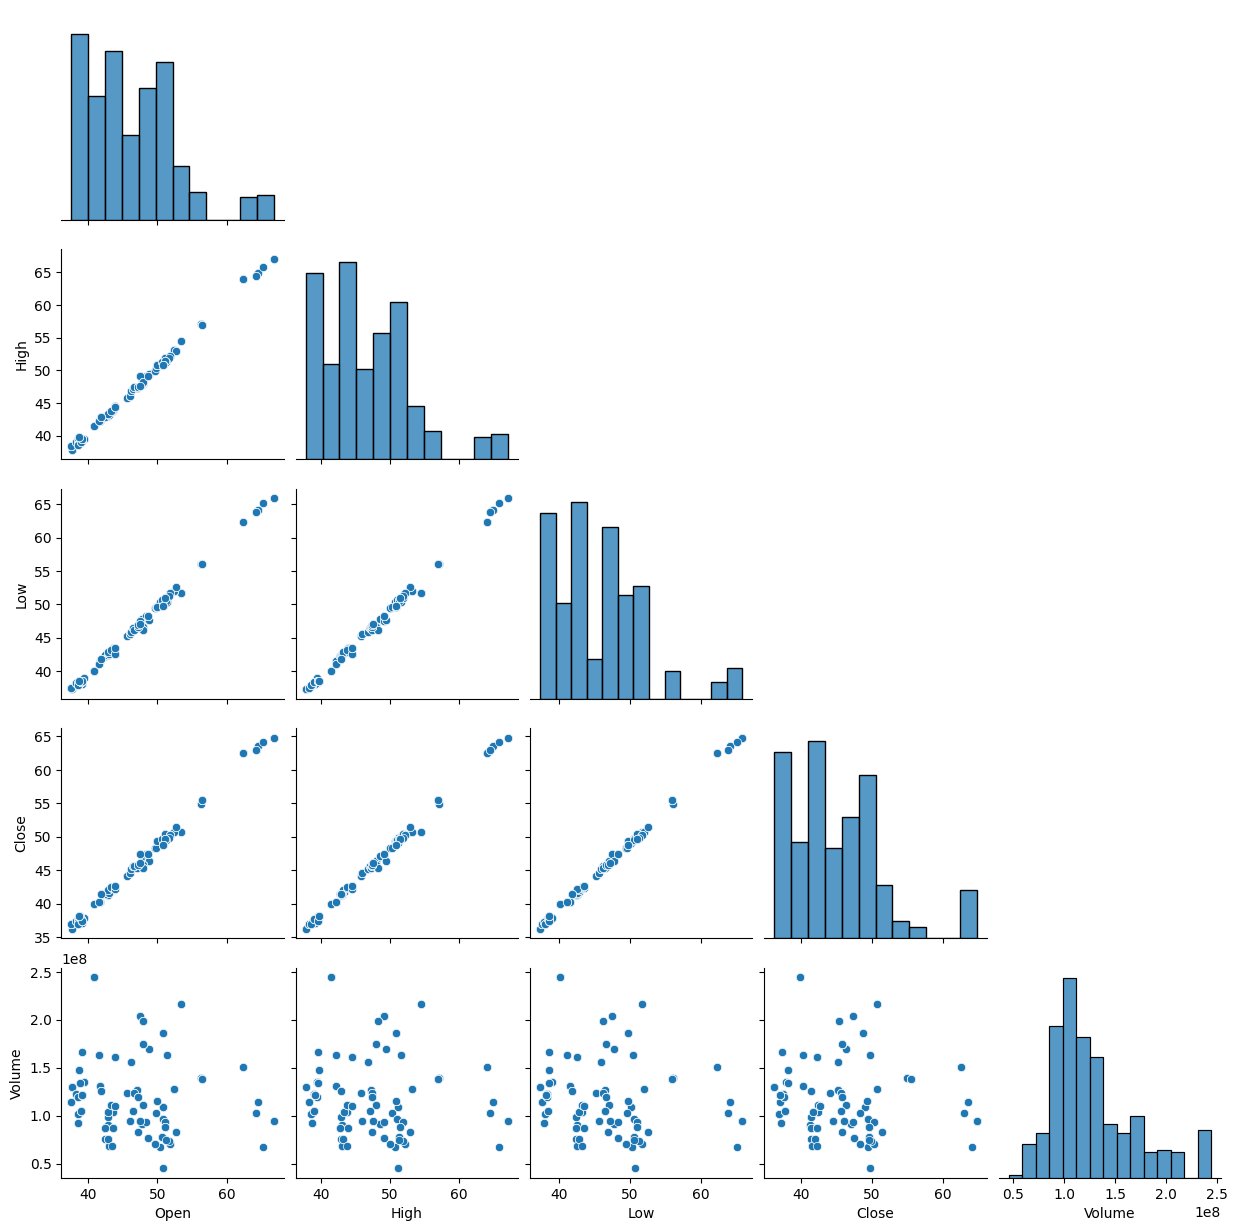

In [23]:
# Plotting a pairplot for all numerical features
sns.pairplot(numeric_df, corner=True);

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>
    
<b>1. Perfect Correlation Among Price Variables:</b> The Open, High, Low, and Close prices all have a correlation of 1. This suggests that the dataset might contain duplicate or highly similar values across these columns.<br><b>2. Weak Negative Correlation Between Volume and Price:</b> The Volume column has weak negative correlations (almost no correlation) with price-related columns:<br>

*   Open vs Volume: -0.067<br>
*   High vs Volume: -0.046<br>
*   Low vs Volume: -0.1<br>
*   Close vs Volume: -0.08<br>

<br>This indicates that trading volume has little to no impact on price changes in this dataset.<br>

A correlation of 1 across all price-related variables suggests that they may not be independent.

<b>Sentiment i.e. Label vs. Closing Price

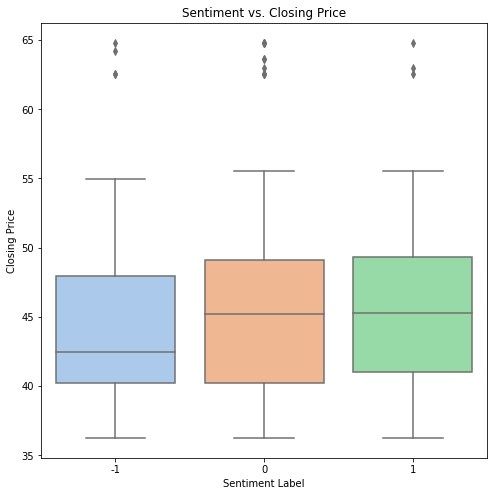

In [8]:
plt.figure(figsize=(8,8))
sns.boxplot(x=stock_df['Label'], y=stock_df['Close'], palette="pastel")
plt.title("Sentiment vs. Closing Price")
plt.xlabel("Sentiment Label")
plt.ylabel("Closing Price")
plt.show()

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br></p>
    
1.   The median closing price is similar across sentiment labels (0, 1), but lower in the sentiment label (-1), indicating that a negative sentiment results in lower closing price.<br>
2.   There are some outliers in all sentiment categories, indicating price variations beyond the typical range.


<b>Sentiment i.e. Label vs. Stock Volatility/Fluctuation

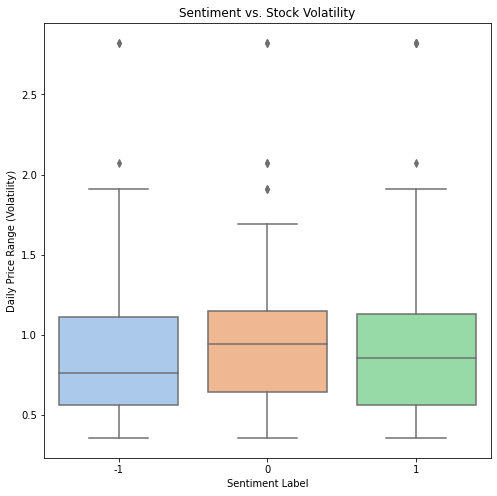

In [9]:
plt.figure(figsize=(8,8))
stock_df['Volatility'] = stock_df['High'] - stock_df['Low'] #Feature Engineered column

sns.boxplot(x=stock_df['Label'], y=stock_df['Volatility'], palette="pastel")
plt.title("Sentiment vs. Stock Volatility")
plt.xlabel("Sentiment Label")
plt.ylabel("Daily Price Range (Volatility)")
plt.show()

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font></p><br>
    
1.   The volatility (daily high - low range) remains similar across positive and negative sentiment labels but volatility is lower in neutral sentiment.<br>
2.   There are some outliers in all sentiment categories, indicating price variations beyond the typical range.<br>
3. Negative sentiment has lowest mean Daily price range.

<b>Volume vs. Sentiment i.e. Label

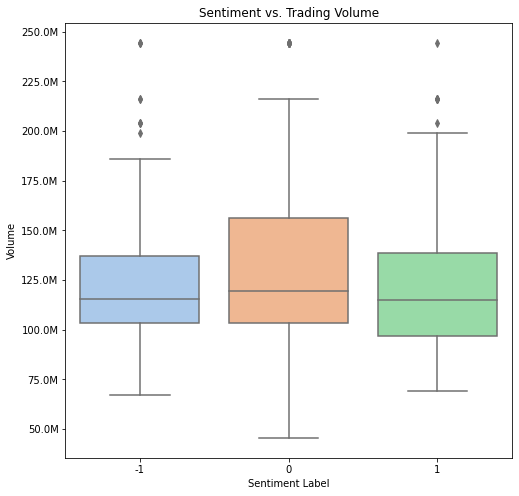

In [10]:
import matplotlib.ticker as ticker

plt.figure(figsize=(8,8))
ax = sns.boxplot(x=stock_df['Label'], y=stock_df['Volume'], palette="pastel")
plt.title("Sentiment vs. Trading Volume")
plt.xlabel("Sentiment Label")
plt.ylabel("Volume")

# Formatting y-axis to show numbers in millions (M)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M'))

plt.show()

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font></p><br>
    
1.   The neutral sentiment (0) appears to have a slightly higher median trading volume than positive (1) and negative (-1) sentiments.
<br>
2.   Outliers show some extreme trading volumes, indicating occasional large-volume trading regardless of sentiment.<br>

<b>Sentiment Trend over Time

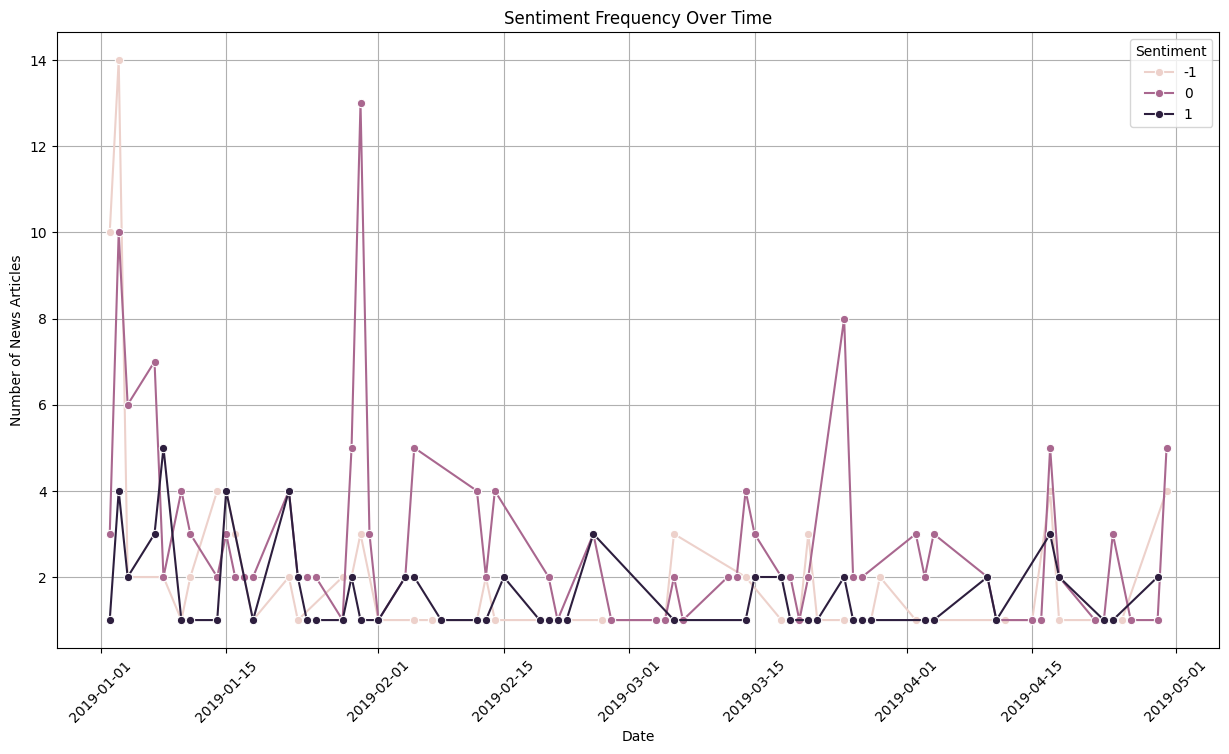

In [27]:
# Counting occurrences of each sentiment per date
sentiment_counts = stock_df.groupby(['Date', 'Label']).size().reset_index(name='Count')

# Plotting sentiment trends
plt.figure(figsize=(15, 8))
sns.lineplot(x='Date', y='Count', hue='Label', data=sentiment_counts, marker="o")

plt.title("Sentiment Frequency Over Time")
plt.xlabel("Date")
plt.ylabel("Number of News Articles")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.grid(True)
plt.show()

<b>Stacked Bar Chart for Sentiment Proportions

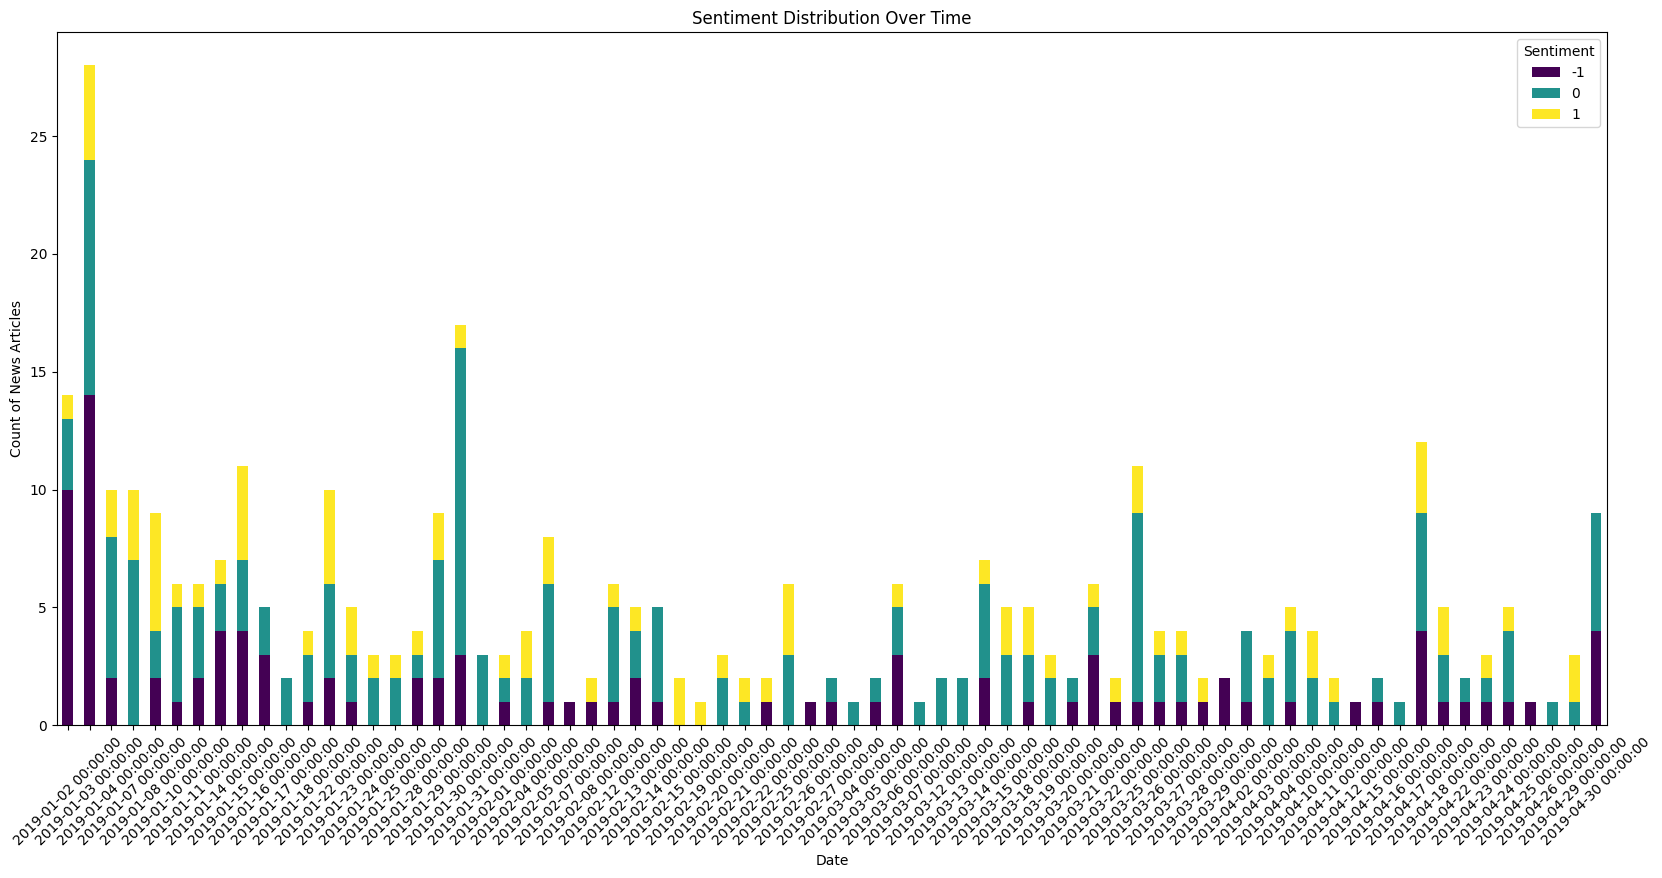

In [28]:
# Pivot table to reshape data for stacking
sentiment_pivot = stock_df.groupby(['Date', 'Label']).size().unstack(fill_value=0)

# Plotting stacked bar chart
sentiment_pivot.plot(kind='bar', stacked=True, figsize=(20, 9), colormap="viridis")

plt.title("Sentiment Distribution Over Time")
plt.xlabel("Date")
plt.ylabel("Count of News Articles")
plt.legend(title="Sentiment")
plt.xticks(rotation=45)
plt.show()

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font></p><br>
    
<b>1. Sentiment Frequency Over Time (Line Chart):</b><br>
The frequency of news articles fluctuates over time, with some spikes indicating key events.
Neutral sentiment (0) appears more frequently than positive (1) and negative (-1) sentiment.
Sentiment variations indicate that certain dates had significant market-relevant news.<br>

<b>2. Sentiment Distribution Over Time (Stacked Bar Chart):</b><br>
The stacked bar chart provides a clearer breakdown of sentiment proportions per day.
Positive sentiment (yellow) is generally dominant, followed by neutral (green) and negative (purple) sentiment. Some days have only one kind of sentiment.<br>

<h1 style="font-family:'Times New Roman';"><font color='navy'> 2. Data Preprocessing </font></h1>

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>2.1 Split the target variable and predictors</b></font></h3>

In [29]:
from sklearn.model_selection import train_test_split

# Defining predictors (X) and target variable (Y)
# Dropping Date as it is not a feature that directly affects the sentiment
X = stock_df.drop(labels= ['Label','Date'],axis = 1)
#Target variable (sentiment)
Y = stock_df['Label']

In [30]:
X.sample(5)

,News,Open,High,Low,Close,Volume,Volatility
109,U.S. futures rose on Friday following reports...,39.375000,39.470001,38.994999,37.902481,135004000,0.475002
23,"Gold prices reached within $5 of $1,300 on Th...",43.570000,43.787498,43.222500,42.470604,103544800,0.564998
184,"This week, the European Union's second highes...",66.817497,67.062500,65.862503,64.805229,94487200,1.199997
185,Akamai Technologies reported stronger than pr...,66.817497,67.062500,65.862503,64.805229,94487200,1.199997
221,"In the news article, Michael Jackson's music ...",52.722500,52.959999,52.557499,51.398247,83569600,0.402500


In [31]:
Y.sample(5)

,Label
4,-1
230,0
172,0
298,0
97,-1


<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>2.2 Split the data into train, validation, and test sets</b></font></h3>

In [32]:
from sklearn.model_selection import train_test_split

# First, splitting data into train (80%) and temp (20%) using one `train_test_split`
X_train, X_temp, y_train, y_temp = train_test_split(X, Y, test_size=0.2, random_state=42)

# Second, splitting temp into validation (50% of temp) and test (50% of temp), resulting in 10% test and 10% validation
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Printing dataset sizes
print(f"Train size: {len(X_train)}, Validation size: {len(X_val)}, Test size: {len(X_test)}")

Train size: 279, Validation size: 35, Test size: 35


In [33]:
# Converting y_train, y_val, and y_test to numeric for model training and evaluation.
y_train = y_train.astype(int)
y_val = y_val.astype(int)
y_test = y_test.astype(int)

# Checking their unique values to confirm
print(y_train.unique())
print(y_val.unique())
print(y_test.unique())

[ 0 -1  1]
[ 1 -1  0]
[-1  0  1]


<h1 style="font-family:'Times New Roman';"><font color='navy'> 3. Word Embeddings </font></h1>

In [34]:
# to use regular expressions for manipulating text data
import re

# to load the natural language toolkit
import nltk
nltk.download('stopwords')    # loading the stopwords
nltk.download('wordnet')    # loading the wordnet module that is used in stemming

# to remove common stop words
from nltk.corpus import stopwords

# to perform stemming
from nltk.stem.porter import PorterStemmer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [35]:
# To import Word2Vec
from gensim.models import Word2Vec
# To load and work with pre-trained word vectors
from gensim.models import KeyedVectors

In [36]:
# Loading the Porter Stemmer and Initializing
ps = PorterStemmer()

In [37]:
def preprocess_text(text):

  ''' Function to clean the text'''

  # Converting to lowercase
  text = text.lower()

  # Removing special characters and numbers
  text = re.sub(r'[^A-Za-z\s]', '', text)

  # Removing extra whitespaces
  text = re.sub(r'\s+', ' ', text).strip()

  # Splitting text into separate words
  words = text.split()

  # Removing English language stopwords
  text = ' '.join([word for word in words if word not in stopwords.words('english')])

  # Applying the Porter Stemmer on every word of a message and joining the stemmed words back into a single string
  text = ' '.join([ps.stem(word) for word in words])

  return text

In [38]:
# preprocessing the textual column i.e. 'News'
X_train['News_Clean'] = X_train['News'].apply(preprocess_text)
X_test['News_Clean'] = X_test['News'].apply(preprocess_text)
X_val['News_Clean'] = X_val['News'].apply(preprocess_text)

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>3.1 Using Word2Vec </b></font></h3>

In [39]:
# Creating a list of all words in our data
words_list = [item.split(" ") for item in X_train['News_Clean'].values]

In [40]:
# Creating an instance of Word2Vec
vec_size = 300
model_W2V = Word2Vec(words_list, vector_size = vec_size, min_count = 1, window=5, workers = 6)

In [41]:
# Checking the size of the vocabulary
print("Length of the vocabulary is", len(list(model_W2V.wv.key_to_index)))

Length of the vocabulary is 2338


In [42]:
# Checking the word embedding of a random word
word = "stock"
print(model_W2V.wv[word])

[ 7.52938259e-03  1.15874298e-01 -6.40220300e-04  6.76510930e-02
 -1.54516697e-02 -1.17007516e-01  7.12795332e-02  2.27696896e-01
  1.55174090e-02 -5.28212003e-02  3.13403010e-02 -1.05718307e-01
 -6.74103014e-03 -4.85108187e-03 -9.20047164e-02 -8.65105242e-02
  9.10091326e-02 -2.30478402e-02  3.71031873e-02 -4.48970385e-02
 -6.38542473e-02 -2.74358597e-02  6.81236163e-02  2.69116629e-02
  7.58755729e-02  9.95839946e-03 -1.13738537e-01 -7.00108940e-03
 -5.89004271e-02 -1.26353055e-01  3.57383192e-02 -5.66453040e-02
  1.16542364e-02  2.66101051e-05 -1.69364512e-02  3.33848670e-02
  2.69820597e-02 -1.33807018e-01 -2.22779196e-02 -5.41111571e-04
 -4.35623825e-02  2.84253526e-02  2.75300187e-03 -1.10210426e-01
  3.93003374e-02  1.04780421e-01 -7.89689599e-04  3.02545410e-02
 -3.58475670e-02  7.40569159e-02  8.78693536e-03 -1.03625190e-02
 -7.99160525e-02  5.82336225e-02 -4.52028513e-02  7.96753317e-02
  5.31648062e-02  4.08168416e-03  2.16311980e-02 -1.95401814e-02
 -4.93871570e-02 -4.86270

In [43]:
# Retrieving the words present in the Word2Vec model's vocabulary
words = list(model_W2V.wv.key_to_index.keys())

# Retrieving word vectors for all the words present in the model's vocabulary
wvs = model_W2V.wv[words].tolist()

# Creating a dictionary of words and their corresponding vectors
word_vector_dict = dict(zip(words, wvs))

In [44]:
def average_vectorizer_Word2Vec(doc):
    """
    Converts a document (sentence) into an average word vector using Word2Vec embeddings.

    Parameters:
    doc (str): Input text/document.

    Returns:
    np.ndarray: Averaged word vector representation of the document.
    """

    # Initializing a feature vector for the sentence
    feature_vector = np.zeros((vec_size,), dtype="float64")

    # Creating a list of words in the sentence that are present in the model vocabulary
    words_in_vocab = [word for word in doc.split() if word in words]

    # Adding the vector representations of the words
    for word in words_in_vocab:
        feature_vector += np.array(word_vector_dict[word])

    # Dividing by the number of words to get the average vector
    if len(words_in_vocab) != 0:
        feature_vector /= len(words_in_vocab)

    return feature_vector

In [45]:
# Converting the datasets
X_train_w2v = np.array(X_train['News_Clean'].apply(average_vectorizer_Word2Vec).tolist())
X_val_w2v = np.array(X_val['News_Clean'].apply(average_vectorizer_Word2Vec).tolist())
X_test_w2v = np.array(X_test['News_Clean'].apply(average_vectorizer_Word2Vec).tolist())

# Converting to DataFrame for visualizing
df_train_w2v = pd.DataFrame(X_train_w2v, columns=['Feature '+ str(i) for i in range(vec_size)])
df_val_w2v = pd.DataFrame(X_val_w2v, columns=['Feature '+ str(i) for i in range(vec_size)])
df_test_w2v = pd.DataFrame(X_test_w2v, columns=['Feature '+ str(i) for i in range(vec_size)])

# Displaying the shape of the transformed data
print(f"Train Shape: {df_train_w2v.shape}, Validation Shape: {df_val_w2v.shape}, Test Shape: {df_test_w2v.shape}")

Train Shape: (279, 300), Validation Shape: (35, 300), Test Shape: (35, 300)


In [46]:
df_train_w2v.head() #Embedded text

,Feature 0,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5,Feature 6,Feature 7,Feature 8,Feature 9,...,Feature 290,Feature 291,Feature 292,Feature 293,Feature 294,Feature 295,Feature 296,Feature 297,Feature 298,Feature 299
0,0.005325,0.071869,0.001792,0.045249,-0.008984,-0.074956,0.046094,0.147005,0.011405,-0.033571,...,0.013281,0.084247,0.038055,0.000540,0.074401,0.085941,0.008684,-0.049820,0.038774,-0.013771
1,0.005889,0.077231,0.002122,0.048437,-0.009380,-0.080351,0.049930,0.157797,0.012328,-0.035555,...,0.014780,0.091206,0.041232,0.000918,0.079970,0.092625,0.009202,-0.053751,0.041933,-0.014474
2,0.004799,0.064984,0.001350,0.040481,-0.008018,-0.067274,0.041707,0.131956,0.010819,-0.030143,...,0.012554,0.075797,0.034394,0.000903,0.066016,0.076884,0.008155,-0.044523,0.035075,-0.011823
3,0.006539,0.090353,0.002389,0.056580,-0.011030,-0.093590,0.058341,0.183843,0.014668,-0.042012,...,0.017201,0.105875,0.047788,0.000867,0.092627,0.107803,0.010723,-0.062569,0.048830,-0.016934
4,0.004733,0.072978,0.002312,0.046174,-0.009142,-0.075701,0.047487,0.149654,0.012228,-0.033936,...,0.014083,0.085918,0.039726,0.001026,0.075274,0.087435,0.009038,-0.050573,0.039966,-0.013275


<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>3.2 Using GloVe </b></font></h3>

In [ ]:
# loading the Stanford GloVe model
filename = '/content/drive/MyDrive/nlp/glove.6B.100d.txt.word2vec'
glove_model = KeyedVectors.load_word2vec_format(filename, binary=False)

In [48]:
# Checking the size of the vocabulary
print("Length of the vocabulary is", len(glove_model.index_to_key))

Length of the vocabulary is 400000


In [49]:
# Checking the word embedding of a random word
word = "stock"
print(glove_model[word])

[ 8.6341e-01  6.9648e-01  4.5794e-02 -9.5708e-03 -2.5498e-01 -7.4666e-01
 -2.2086e-01 -4.4615e-01 -1.0423e-01 -9.9931e-01  7.2550e-02  4.5049e-01
 -5.9912e-02 -5.7837e-01 -4.6540e-01  4.3429e-02 -5.0570e-01 -1.5442e-01
  9.8250e-01 -8.1571e-02  2.6523e-01 -2.3734e-01  9.7675e-02  5.8588e-01
 -1.2948e-01 -6.8956e-01 -1.2811e-01 -5.2265e-02 -6.7719e-01  3.0190e-02
  1.8058e-01  8.6121e-01 -8.3206e-01 -5.6887e-02 -2.9578e-01  4.7180e-01
  1.2811e+00 -2.5228e-01  4.9557e-02 -7.2455e-01  6.6758e-01 -1.1091e+00
 -2.0493e-01 -5.8669e-01 -2.5375e-03  8.2777e-01 -4.9102e-01 -2.6475e-01
  4.3015e-01 -2.0516e+00 -3.3208e-01  5.1845e-02  5.2646e-01  8.7452e-01
 -9.0237e-01 -1.7366e+00 -3.4727e-01  1.6590e-01  2.7727e+00  6.5756e-02
 -4.0363e-01  3.8252e-01 -3.0787e-01  5.9202e-01  1.3468e-01 -3.3851e-01
  3.3646e-01  2.0950e-01  8.5905e-01  5.1865e-01 -1.0657e+00 -2.6371e-02
 -3.1349e-01  2.3231e-01 -7.0192e-01 -5.5737e-01 -2.3418e-01  1.3563e-01
 -1.0016e+00 -1.4221e-01  1.0372e+00  3.5880e-01 -4

In [50]:
# Retrieving the words present in the GloVe model's vocabulary
glove_vocab = set(glove_model.key_to_index.keys())
vec_size = 100 #glove dimension

In [51]:
def average_vectorizer_GloVe(doc):
  """
    Converts a document (sentence) into an average word vector using GloVe embeddings.

    Parameters:
    doc (str): Input text/document.

    Returns:
    np.ndarray: Averaged word vector representation of the document.
  """

  # Initializing a feature vector for the sentence
  feature_vector = np.zeros((vec_size,), dtype="float64")

  # Creating a list of words in the sentence that are present in the model vocabulary
  words_in_vocab = [word for word in doc.split() if word in glove_vocab]

  # Adding the vector representations of the words
  for word in words_in_vocab:
    feature_vector += glove_model[word]

  # Dividing by the number of words to get the average vector
  if len(words_in_vocab) != 0:
    feature_vector /= len(words_in_vocab)

  return feature_vector

In [52]:
# Converting the datasets
X_train_glove = np.array(X_train['News_Clean'].apply(average_vectorizer_GloVe).tolist())
X_val_glove = np.array(X_val['News_Clean'].apply(average_vectorizer_GloVe).tolist())
X_test_glove = np.array(X_test['News_Clean'].apply(average_vectorizer_GloVe).tolist())

# Converting to DataFrame for visualizing
df_train_glove = pd.DataFrame(X_train_glove, columns=['Feature '+ str(i) for i in range(vec_size)])
df_val_glove = pd.DataFrame(X_val_glove, columns=['Feature '+ str(i) for i in range(vec_size)])
df_test_glove = pd.DataFrame(X_test_glove, columns=['Feature ' + str(i) for i in range(vec_size)])

# Displaying the shape of the transformed data
print(f"Train Shape: {df_train_glove.shape}, Validation Shape: {df_val_glove.shape}, Test Shape: {df_test_glove.shape}")

Train Shape: (279, 100), Validation Shape: (35, 100), Test Shape: (35, 100)


In [53]:
df_train_glove.head() #Embedded text

,Feature 0,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5,Feature 6,Feature 7,Feature 8,Feature 9,...,Feature 90,Feature 91,Feature 92,Feature 93,Feature 94,Feature 95,Feature 96,Feature 97,Feature 98,Feature 99
0,-0.088663,0.038229,0.337367,-0.052827,0.114041,0.097140,-0.178427,0.144213,-0.155560,0.067946,...,-0.062072,-0.094935,-0.296828,0.137671,-0.334059,-0.057383,-0.305797,-0.169217,0.485695,-0.025645
1,0.006213,0.043207,0.053961,-0.020118,-0.003921,-0.213890,-0.283504,0.016783,-0.011186,0.003097,...,0.021825,0.175657,-0.192424,-0.156322,-0.412273,0.032284,-0.055251,-0.215458,0.409624,-0.039618
2,-0.073415,0.091285,0.234732,-0.314618,-0.080300,-0.181707,-0.029966,0.084152,-0.013458,0.011934,...,-0.041476,-0.026719,-0.136394,0.025509,-0.284555,-0.000559,-0.042177,-0.272961,0.360021,0.135459
3,0.097387,0.239222,0.308974,-0.022979,0.148936,-0.406705,-0.272075,-0.062672,-0.239150,-0.041073,...,0.028451,0.086239,-0.070984,-0.072292,-0.488302,0.108359,-0.000310,-0.271435,0.519167,0.081774
4,-0.032709,0.016421,0.317044,-0.109070,0.077740,-0.102717,0.032939,0.147483,-0.120287,0.165059,...,-0.012867,0.038299,-0.158399,-0.041823,-0.466220,0.023129,-0.110019,-0.070833,0.761661,0.009209


<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>3.3 Using Sentence Transformer </b></font></h3>

In [54]:
import gensim
import sentence_transformers

print(gensim.__version__)  # Should print the installed version
print(sentence_transformers.__version__)

4.3.3
3.4.1


In [55]:
from sentence_transformers import SentenceTransformer

# Loading Sentence Transformer model
sentence_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (2 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [56]:
# Converting text data into embeddings
X_train_st = np.array(sentence_model.encode(X_train['News_Clean'].to_list(), show_progress_bar=True))
X_val_st = np.array(sentence_model.encode(X_val['News_Clean'].to_list(), show_progress_bar=True))
X_test_st = np.array(sentence_model.encode(X_test['News_Clean'].to_list(), show_progress_bar=True))

# Converting to DataFrame for visualizing
df_train_st = pd.DataFrame(X_train_st, columns=['Feature '+ str(i) for i in range(X_train_st.shape[1])])
df_val_st = pd.DataFrame(X_val_st, columns=['Feature '+ str(i) for i in range(X_val_st.shape[1])])
df_test_st = pd.DataFrame(X_test_st, columns=['Feature '+ str(i) for i in range(X_test_st.shape[1])])

# Displaying the shape of the transformed data
print(f"Train Shape: {df_train_st.shape}, Validation Shape: {df_val_st.shape}, Test Shape: {df_test_st.shape}")

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Train Shape: (279, 384), Validation Shape: (35, 384), Test Shape: (35, 384)


In [57]:
df_train_st.head() #Embedded text

,Feature 0,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5,Feature 6,Feature 7,Feature 8,Feature 9,...,Feature 374,Feature 375,Feature 376,Feature 377,Feature 378,Feature 379,Feature 380,Feature 381,Feature 382,Feature 383
0,-0.097109,0.049175,0.009956,-0.033751,0.047169,0.027852,0.097380,0.008044,0.017086,0.049375,...,0.040724,-0.038374,0.025233,0.060355,-0.131470,-0.019435,0.029725,0.017861,0.058121,0.027551
1,-0.043175,0.031601,0.020325,0.012358,0.021452,-0.009682,0.008311,0.097691,0.008428,-0.050065,...,0.020446,0.060105,-0.095297,0.008195,-0.034609,0.051145,0.020321,-0.150783,-0.031642,0.038676
2,-0.067011,-0.011238,0.039002,-0.071829,-0.010156,-0.051968,-0.028557,0.034260,0.007028,0.077591,...,0.041114,0.075534,-0.052382,-0.012823,-0.012245,0.013850,0.010704,-0.120875,0.001978,0.009449
3,-0.011982,-0.004453,0.052792,0.085855,0.019047,-0.029342,0.008570,0.030646,-0.010093,0.007874,...,0.009830,0.037247,0.007846,0.002164,-0.038784,0.043992,0.074108,-0.147187,-0.015047,0.103966
4,-0.020781,0.030752,0.015300,-0.028304,-0.009177,0.053127,0.001661,0.112997,-0.055961,-0.044726,...,0.030182,0.042105,-0.036196,-0.007893,-0.094282,-0.043852,0.010741,-0.053720,0.034491,0.101725


<h1 style="font-family:'Times New Roman';"><font color='navy'> 4. Sentiment Analysis </font></h1>

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>4.1 Comment on which metric to use and why </b></font></h3>

<b>Metrics to Use for Sentiment Analysis:</b><br>

1. Accuracy: Measures the proportion of correct predictions. It is best when the dataset is balanced. In this dataset, this is not true.<br>
2. Precision, Recall, F1-Score: More relevant for imbalanced datasets.<br>

*   Precision for '-1' label measures how many of the negative sentiment predictions were actually correct.
*   Detecting negative sentiment (-1) is more important due to the typically more substantial market movements associated with negative news, which can directly impact strategic decision-making in stock investments. Doing so will help us to avoid loss situation. This is crucial for protecting the capital of  traders.
*   Consecutively, F1-Score can be also looked at for '-1' label which is the harmonic mean of precision and recall. Best for imbalanced classes.<br>

3. POINTS TO NOTE:

* Negative Sentiment (-1) is most critical: Investors react strongly to negative news, so accurate detection of -1 sentiment is crucial for risk mitigation and timely decision-making.

* Neutral Sentiment (0) should be well captured: Proper classification ensures that neutral news isn’t mistaken for impactful events.

* Positive Sentiment (1) is also important but less critical than -1.

A balanced model that captures all sentiments (-1, 0, 1) accurately is the optimal fit.

Since sentiment analysis can have class imbalance, and the data given is imbalanced, <b><i>I recommend using F1-score as the primary metric</b></i>.<br>
NOTE: '0' sentiment can also be focused if detecting the neutral sentiment of the market is of priority in case of analysts and financial sentiment research.

In [58]:
from sklearn.metrics import confusion_matrix

# Function to plot the confusion matrix
def plot_confusion_matrix(actual, predicted):

    cm = confusion_matrix(actual, predicted)

    plt.figure(figsize = (5, 5))
    label_list = ['Negative', 'Neutral', 'Positive']
    sns.heatmap(cm, annot = True,  fmt = '.0f', xticklabels = label_list, yticklabels = label_list)
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

In [59]:
# Function to evaluate the model
def evaluate_model(model, X_val, y_val, model_name):

    """
    Evaluates the trained model on the passed data.

    Parameters:
    - model: Trained model
    - X_val: Validation feature matrix
    - y_val: Validation labels
    - model_name: Name of the model for display

    Returns:
    - Dictionary with evaluation metrics
    """

    y_pred = model.predict(X_val)

    accuracy = accuracy_score(y_val, y_pred)
    class_report = classification_report(y_val, y_pred, zero_division=0, digits=4)

    print(f"=== {model_name} ===")
    print(f"Accuracy: {accuracy:.4f}\n")
    print("Classification Report:\n", class_report)

    return {"accuracy": accuracy, "report": class_report}

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>4.2 Build a ML model with each of the following embedding techniques - Word2Vec - GloVe - Sentence Transformer </b></font></h3>

<b>

*  Using Random Forest is ideal for stock news sentiment analysis because it handles non-linearity, reduces overfitting, and manages imbalanced sentiment classes effectively.

*   It works well with high-dimensional text data, is robust to noise, and provides feature importance for explainability.

* It is faster and easier to interpret, making it a strong choice for stock sentiment analysis.

In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Function to train the model
def train_random_forest(X_train, y_train, n_estimators=100, max_depth=None):
    """
    Trains a Random Forest classifier on the given data.

    Parameters:
    - X_train: Training feature matrix
    - y_train: Training labels
    - n_estimators: Number of trees in the forest (default=100)
    - max_depth: Maximum depth of the trees (default=None, fully grown trees)

    Returns:
    - Trained RandomForest model
    """

    rf_model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)
    rf_model.fit(X_train, y_train)

    return rf_model

<b>Random Forest on Word2Vec

In [61]:
rf_w2v = train_random_forest(X_train_w2v, y_train)
eval_w2v = evaluate_model(rf_w2v, X_val_w2v, y_val, "Random Forest - Word2Vec")

=== Random Forest - Word2Vec ===
Accuracy: 0.3143

Classification Report:
               precision    recall  f1-score   support

          -1     0.0000    0.0000    0.0000        14
           0     0.3793    0.7333    0.5000        15
           1     0.0000    0.0000    0.0000         6

    accuracy                         0.3143        35
   macro avg     0.1264    0.2444    0.1667        35
weighted avg     0.1626    0.3143    0.2143        35



<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>

1. **Low Overall Accuracy (31.4%)**  
   - The model's accuracy is low, indicating poor classification performance.  
   - Word2Vec features might not be effectively capturing the relevant information for classification.  

2. **Class Imbalance Issues**  
   - The dataset appears to be imbalanced, particularly for classes -1 and 1.  
   - This imbalance might be affecting the model’s ability to generalize well across all categories.  

3. **Poor Performance for Negative (-1) and Positive (1) Classes**  
   - Precision, Recall, and F1-score for both -1 and 1 are 0.00, meaning the model fails to correctly classify these instances.  
   - The model only performs somewhat better on class 0 but still lacks strong predictive power.  

4. **Potential Reasons for Poor Performance**  
   - Feature extraction via Word2Vec may not be optimized for this task.  
   - The dataset size might be too small, leading to poor learning of word embeddings.  


<b>Random Forest on GloVe

In [62]:
rf_glove = train_random_forest(X_train_glove, y_train)
eval_glove = evaluate_model(rf_glove, X_val_glove, y_val, "Random Forest - GloVe")

=== Random Forest - GloVe ===
Accuracy: 0.4571

Classification Report:
               precision    recall  f1-score   support

          -1     0.4444    0.2857    0.3478        14
           0     0.4615    0.8000    0.5854        15
           1     0.0000    0.0000    0.0000         6

    accuracy                         0.4571        35
   macro avg     0.3020    0.3619    0.3111        35
weighted avg     0.3756    0.4571    0.3900        35



<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>

1. **Moderate Improvement in Accuracy (45.71%)**  
   - The model performs better than Word2Vec (31.4%) but still lacks strong predictive capability.  
   - This suggests that GloVe embeddings provide a slightly better word representation for classification.  

2. **Class Imbalance Issues Persist**  
   - The model struggles with classifying the positive (1) class, where precision, recall, and F1-score are all 0.00.  
   - Class 0 has the best performance, with an F1-score of 0.5854, meaning the model is more reliable for neutral sentiments.  

3. **Better Performance for Neutral (0) Class**  
   - The model predicts class 0 relatively well, with a recall of 80%, meaning it captures most of the actual neutral cases.  
   - However, it still misclassifies a significant portion of the negative (-1) and positive (1) instances.  

4. **Potential Reasons for Poor Performance**  
   - GloVe embeddings might still not fully capture the financial sentiment nuances.  
   - The dataset size may be too small for Random Forest to learn meaningful patterns from word embeddings.


<b>Random Forest on Sentence Transformer

In [63]:
rf_st = train_random_forest(X_train_st, y_train)
eval_st = evaluate_model(rf_st, X_val_st, y_val, "Random Forest - Sentence Transformer")

=== Random Forest - Sentence Transformer ===
Accuracy: 0.4857

Classification Report:
               precision    recall  f1-score   support

          -1     0.5000    0.2857    0.3636        14
           0     0.4800    0.8000    0.6000        15
           1     0.5000    0.1667    0.2500         6

    accuracy                         0.4857        35
   macro avg     0.4933    0.4175    0.4045        35
weighted avg     0.4914    0.4857    0.4455        35



<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>

1. **Improved Accuracy (48.57%)**  
   - The model achieves the highest accuracy so far (48.57%), improving over both Word2Vec (31.4%) and GloVe (45.71%).

2. **Balanced Performance Across Classes**  
   - Unlike Word2Vec and GloVe, the model shows some ability to classify all three classes.
   - The positive (1) class now has non-zero precision, recall, and F1-score, though it is still the weakest class. 

3. **Better Recall for Neutral (0) Class**  
   - The model performs best on class 0 (neutral sentiment), with a recall of 80% and an F1-score of 0.60.  
   - This indicates the model is good at detecting neutral events but still struggles with extreme sentiment (positive/negative).  

4. **Challenges in Classifying Negative (-1) and Positive (1) Sentiments**  
   - Negative (-1) ClassPrecision is 50%, but recall is only 28.57%, meaning many negative events are misclassified.  
   - Positive (1) Class:Precision is 50%, but recall is very low (16.67%), meaning the model predicts positive events too rarely.  

5. **Potential Reasons for Performance Trends**   
   - Class imbalance remains a problem, with the model biased toward neutral predictions.  
   - Small dataset size limits generalization, especially for the positive class.

 <b>Comparing Model Performance

In [64]:
results = {
    "Word2Vec": eval_w2v,
    "GloVe": eval_glove,
    "Sentence Transformer": eval_st
}

# Display results for each model
for model_name, metrics in results.items():
    print(f"=== {model_name} === - Accuracy: {metrics['accuracy']:.4f}, \n\nReport: {metrics['report']:}\n\n")

=== Word2Vec === - Accuracy: 0.3143, 

Report:               precision    recall  f1-score   support

          -1     0.0000    0.0000    0.0000        14
           0     0.3793    0.7333    0.5000        15
           1     0.0000    0.0000    0.0000         6

    accuracy                         0.3143        35
   macro avg     0.1264    0.2444    0.1667        35
weighted avg     0.1626    0.3143    0.2143        35



=== GloVe === - Accuracy: 0.4571, 

Report:               precision    recall  f1-score   support

          -1     0.4444    0.2857    0.3478        14
           0     0.4615    0.8000    0.5854        15
           1     0.0000    0.0000    0.0000         6

    accuracy                         0.4571        35
   macro avg     0.3020    0.3619    0.3111        35
weighted avg     0.3756    0.4571    0.3900        35



=== Sentence Transformer === - Accuracy: 0.4857, 

Report:               precision    recall  f1-score   support

          -1     0.5000    0.

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>

1. Overall Model Comparison<br>
   - Sentence Transformer (48.57%) achieved the highest accuracy, followed by GloVe (45.71%) and Word2Vec (31.4%).<br>
   - However, accuracy alone is not reliable due to class imbalance. F1-score matters more, particularly for the negative (-1) class, which is the most important for stock market impact as stated before.<br><br>
2. Word2Vec Model Performance (Poor for Negative Sentiment) <br>
   - Very poor performance for negative (-1) sentiment, with 0.00 F1-score, meaning it failed to classify any negative events. <br> 
   - Neutral (0) class performed relatively better, with an F1-score of 0.5 but still not ideal. <br> 
   - The model is not suitable for financial sentiment analysis, as missing negative signals could lead to incorrect stock predictions.<br><br>

3. GloVe Model Performance (Somewhat Better, Still Weak on Negatives)<br> 
   - Slightly better than Word2Vec, but negative (-1) detection is still weak, with an F1-score of 0.3478.<br>
   - The neutral (0) class has the best performance, with an F1-score of 0.5854, meaning it captures most neutral events.<br>  
   - Fails to classify positive (1) events, which is less important but still indicates model limitations.<br><br> 

4. Sentence Transformer Model (Best Model, But Still Needs Improvement on -1 Class) 
   - Best overall performance, but still weak on negative (-1) class (F1-score: 0.3636) <br> 
   - Neutral (0) class is handled well, with the highest F1-score of 0.6000, meaning the model effectively identifies market-stable events.<br>  
   - Positive (1) class now has some detection ability, though F1-score remains low (0.2500).  <br>
   - This is the best performing model so far, but still not fully reliable for detecting negative market-moving events.</p>  

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>4.3 Perform hyperparameter tuning for the ML model for each of the following embedding techniques - Word2Vec - GloVe - Sentence Transformer</b></font></h3>

In [74]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold

# Defining parameter grid for Random Forest
param_grid = {
    'max_depth': [3, 5, 7],
    'n_estimators': [50, 100, 150],
    'max_features': [0.3, 0.5, 0.7]
}

# Function to tune the Random Forest models
def tune_random_forest(X_train, y_train):
    """
    Tunes the hyperparameters of a Random Forest classifier.

    Parameters:
    - X_train: Training feature matrix
    - y_train: Training labels

    Returns:
    - Tuned RandomForest model
    """

    rf = RandomForestClassifier(random_state=42)

    # Initializing Stratified K-Fold with 5 splits
    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=cv_strategy, scoring='f1_weighted', n_jobs=-1)
    grid_search.fit(X_train, y_train)

    print(f"Best Parameters: {grid_search.best_params_}")

    return grid_search.best_estimator_

In [75]:
# Tuning for Word2Vec embeddings
best_rf_w2v = tune_random_forest(X_train_w2v, y_train)

Best Parameters: {'max_depth': 7, 'max_features': 0.3, 'n_estimators': 50}


In [76]:
# Tuning for GloVe embeddings
best_rf_glove = tune_random_forest(X_train_glove, y_train)

Best Parameters: {'max_depth': 7, 'max_features': 0.3, 'n_estimators': 50}


In [77]:
# Tuning for Sentence Transformer embeddings
best_rf_st = tune_random_forest(X_train_st, y_train)

Best Parameters: {'max_depth': 7, 'max_features': 0.5, 'n_estimators': 50}


<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>4.4 Comment on model performance across different metrics</b></font></h3>

In [78]:
eval_w2v = evaluate_model(best_rf_w2v, X_val_w2v, y_val, "Random Forest Tuned - Word2Vec ")

=== Random Forest Tuned - Word2Vec  ===
Accuracy: 0.3429

Classification Report:
               precision    recall  f1-score   support

          -1     0.2000    0.0714    0.1053        14
           0     0.3793    0.7333    0.5000        15
           1     0.0000    0.0000    0.0000         6

    accuracy                         0.3429        35
   macro avg     0.1931    0.2683    0.2018        35
weighted avg     0.2426    0.3429    0.2564        35



<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>

**Word2Vec Model Performance (Slightly Improved, But Still Weak on Negative Sentiment)**
   - Negative (-1) detection is still very poor, with an F1-score of 0.1053 meaning it misses most important negative market signals.  
   - Neutral (0) class has the best performance with F1-score of 0.5000 meaning the model is somewhat decent at identifying neutral stock-related news.  
   - Fails completely to detect positive (1) sentiment, with an F1-score of 0.0000.  
   - Overall, this model remains unsuitable for financial sentiment analysis, as it cannot reliably detect critical negative news.

In [79]:
eval_glove = evaluate_model(best_rf_glove, X_val_glove, y_val, "Random Forest Tuned - GloVe")

=== Random Forest Tuned - GloVe ===
Accuracy: 0.4571

Classification Report:
               precision    recall  f1-score   support

          -1     0.5455    0.4286    0.4800        14
           0     0.4348    0.6667    0.5263        15
           1     0.0000    0.0000    0.0000         6

    accuracy                         0.4571        35
   macro avg     0.3267    0.3651    0.3354        35
weighted avg     0.4045    0.4571    0.4176        35



<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>

**GloVe Model Performance (Moderate Improvement)**
   - Negative (-1) detection has improved slightly with an F1-score of 0.48.
   - Neutral (0) sentiment detection is strong, with F1-score of 0.5263 meaning it identifies stable, non-market-moving news effectively.  
   - Still unable to classify positive (1) sentiment events which suggests a potential limitation in word embeddings for sentiment differentiation.  
   - Overall, a better model than Word2Vec.

In [80]:
eval_st = evaluate_model(best_rf_st, X_val_st, y_val, "Random Forest Tuned - Sentence Transformer")

=== Random Forest Tuned - Sentence Transformer ===
Accuracy: 0.4571

Classification Report:
               precision    recall  f1-score   support

          -1     0.4286    0.2143    0.2857        14
           0     0.4800    0.8000    0.6000        15
           1     0.3333    0.1667    0.2222         6

    accuracy                         0.4571        35
   macro avg     0.4140    0.3937    0.3693        35
weighted avg     0.4343    0.4571    0.4095        35



<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>
    
**Sentence Transformer Model (Overall fine Performance, but Needs Further Improvement on -1 Class)**
   - Negative (-1) F1-score of 0.2857.
   - Neutral (0) sentiment detection is the strongest, with F1-score of 0.6000, making it highly effective at identifying stable stock-related news.  
   - Positive (1) sentiment detection has decreased, with F1-score of 0.33 from 0.35. 
   - This model is the best among the three, but still lacks strong enough negative (-1) sentiment detection for financial predictions which is crucial

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>4.5 Choose the best model from the ones built with proper reasoning</b></font></h3>

In [81]:
results2 = {
    "Word2Vec": eval_w2v,
    "GloVe": eval_glove,
    "Sentence Transformer": eval_st
}

# Display results for each model (Un-Tuned)
print("\n*******------------- Un-Tuned Models *******-------------\n ")
for model_name, metrics in results.items():
    print(f"=== {model_name} === - Accuracy: {metrics['accuracy']:.4f}, \nReport: {metrics['report']:}\n")

# Display results for each model (Tuned)
print("\n\n*******------------- Tuned Models *******-------------\n\n ")
for model_name, metrics in results2.items():
    print(f"=== {model_name} === - Accuracy: {metrics['accuracy']:.4f}, \nReport: {metrics['report']:}\n")


*******------------- Un-Tuned Models *******-------------
 
=== Word2Vec === - Accuracy: 0.3143, 
Report:               precision    recall  f1-score   support

          -1     0.0000    0.0000    0.0000        14
           0     0.3793    0.7333    0.5000        15
           1     0.0000    0.0000    0.0000         6

    accuracy                         0.3143        35
   macro avg     0.1264    0.2444    0.1667        35
weighted avg     0.1626    0.3143    0.2143        35


=== GloVe === - Accuracy: 0.4571, 
Report:               precision    recall  f1-score   support

          -1     0.4444    0.2857    0.3478        14
           0     0.4615    0.8000    0.5854        15
           1     0.0000    0.0000    0.0000         6

    accuracy                         0.4571        35
   macro avg     0.3020    0.3619    0.3111        35
weighted avg     0.3756    0.4571    0.3900        35


=== Sentence Transformer === - Accuracy: 0.4857, 
Report:               precision    r

<p style="font-family:'Georgia'; font-size:15px;"><font color='darkred'><b>Observations:</b></font><br>

<b>Glove + Random Forest (Tuned)</b> is the best model because of the following:<br>
*   Highest F1-score for negative (-1) sentiment (0.48) → better at detecting stock market downturns. → Balances precision & recall. (most critical)<br>
*   Strong neutral (0) sentiment F1-score (0.52) → useful for stable news classification.<br>
*   Strong neutral (0) sentiment recall (0.66)<br>
*   Higher Recall (-1 = 0.42) → Captures more actual negatives.<br>
*   Decent Precision (-1 = 0.54) → Fewer false positives for negative sentiment.<br>
*   Overall accuracy (45.7%).<br>
*   Fails to capture '1' but can be Tuned further for improvement.
<br>
    Glove + Random Forest (Tuned) still needs further improvement in positive (1) detection before being deployed for stock market news analysis. <br>

<b>Points considered for the selection:</b><br>
* Negative sentiment is most critical. It performs the best for detecting it out of all the Tuned and Un-Tuned models.<br>
* Stock prices react to both positive and negative sentiment.<br>
* Neutral sentiment (0) is important to filter out noise.<br>
* Further tuning can be done for better results on positive sentiment.<br>

    <b><i>Thus, I select Glove + Random Forest (Tuned) as the Final model.</i></b>
</p>

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>4.6 Check the performance of the final model on the test set</b></font></h3>

In [87]:
eval_model = evaluate_model(best_rf_glove, X_test_glove, y_test, "Glove + Random Forest (Tuned) on Test Data ")

=== Glove + Random Forest (Tuned) on Test Data  ===
Accuracy: 0.4857

Classification Report:
               precision    recall  f1-score   support

          -1     0.4000    0.3333    0.3636         6
           0     0.5000    0.8750    0.6364        16
           1     0.5000    0.0769    0.1333        13

    accuracy                         0.4857        35
   macro avg     0.4667    0.4284    0.3778        35
weighted avg     0.4829    0.4857    0.4028        35



**Final Decision: GloVe (Tuned) is the Better Model**
* Performs more consistently across validation and test sets. Infact, performs better on the Test Data.
* F1-score remains consistent across categories.
* Captures negative (-1) and positive (1) sentiment better. Also able to capture (1) sentiment now on Test data.
* Captures (0) well which is important for getting an idea about the Neutral sentiment and avoid getting into situations with drastic changes in the stock market.
* Higher accuracy on test data (45.7% -> 48.5%)

*INSIGHT: The second best model Sentence Transformer Untuned was showing signs of overfitting while building of the model. While running it on the test data, it was evident that it gave better performance while training but performed worse than the Glove Tuned model on the test data.*<br>

*NOTE: Further Tuning can be done to get better results before deployment.*

<h1 style="font-family:'Times New Roman';"><font color='navy'> 5. Content Summarization </font></h1>

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>5.1 Group the data at a week-level </b></font></h3>

In [ ]:
df = stock_df.copy() #copying the original data

In [ ]:
# Grouping data weekly
weekly_grouped = df.groupby(pd.Grouper(key="Date", freq="W")).agg(
    {
        "News": lambda x: " || ".join(x)  # Join news articles with a separator
    }
).reset_index()

# Copying the weekly data
data_1 = weekly_grouped.copy()

weekly_grouped

,Date,News
0,2019-01-06,The tech sector experienced a significant dec...
1,2019-01-13,Sprint and Samsung plan to release 5G smartph...
2,2019-01-20,The U.S. stock market declined on Monday as c...
3,2019-01-27,"The Swiss National Bank (SNB) governor, Andre..."
4,2019-02-03,Caterpillar Inc reported lower-than-expected ...
5,2019-02-10,"The Dow Jones Industrial Average, S&P 500, an..."
6,2019-02-17,"This week, the European Union's second highes..."
7,2019-02-24,This news article discusses progress towards ...
8,2019-03-03,The Dow Jones Industrial Average and other ma...
9,2019-03-10,"Spotify, the world's largest paid music strea..."


<b> The data is now grouped into 18 weeks.

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>5.2 Load the large language model from Hugging Face </b></font></h3>

In [ ]:
from huggingface_hub import login
login()

In [ ]:
# Installation for GPU llama-cpp-python
!CMAKE_ARGS="-DLLAMA_CUBLAS=on" FORCE_CMAKE=1 pip install llama-cpp-python==0.2.45 --force-reinstall --no-cache-dir -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/36.7 MB ? eta -:--:--
     ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/36.7 MB 39.5 MB/s eta 0:00:01
     ━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/36.7 MB 142.6 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━ 18.9/36.7 MB 256.9 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━ 28.0/36.7 MB 255.5 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺ 35.9/36.7 MB 225.0 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.7/36.7 MB 217.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 99.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 127.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.6/134.6 kB 314.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━

In [ ]:
# For downloading the models from HF Hub
!pip install huggingface_hub datasets -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/480.6 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/116.3 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/179.3 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/143.5 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/194.8 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 17.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.5.1+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform

In [ ]:
# Importing necessary libraries
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import json

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>5.3 Create a function to define the model parameters and generate a response </b></font></h3>

In [ ]:
# Function to define model parameters
def setup_llama_model(model_name_or_path, model_basename, n_threads=2, n_batch=512, n_ctx=4096):
    """
    Function to initialize the Llama model with given parameters.

    Args:
    - model_name_or_path: Hugging Face model identifier.
    - model_basename: Name of the model file to download.
    - n_threads: Number of CPU threads to use for inference.
    - n_batch: Batch size for processing the model.
    - n_ctx: Context window size for the model.

    Returns:
    - lcpp_llm: The initialized Llama model.
    """

    # Downloading model from Hugging Face
    model_path = hf_hub_download(
        repo_id=model_name_or_path,
        filename=model_basename
    )

    # Initializing the Llama model
    lcpp_llm = Llama(
        model_path=model_path,
        n_threads=n_threads,  # Number of CPU threads
        n_batch=n_batch,      # Batch size
        n_ctx=n_ctx,          # Context window size
    )

    return lcpp_llm

In [ ]:
#Defining the response function

def response_mistral(prompt, news):
    model_output = llm(
      f"""
      [INST]
      {prompt}
      News Articles: {news}
      [/INST]
      """,
      max_tokens=500, # the maximum number of tokens the model should generate for this task
      temperature=0, # value for temperature i.e. randomness
      top_p=0.95, # value for top_p
      top_k=50, # value for top_k
      echo=False,
    )


    temp_output = model_output["choices"][0]["text"].strip()

    # Checking if the output contains a '{'
    if '{' in temp_output:
        final_output = temp_output[temp_output.index('{'):]
    else:
        # If '{' is not found
        print("Warning: JSON object not found in model output.")
        final_output = temp_output

    return final_output

In [ ]:
# Defining a function to parse the JSON output from the model..
def extract_json_data(json_str):
    import json
    try:
        # Finding the indices of the opening and closing curly braces
        json_start = json_str.find('{')
        json_end = json_str.rfind('}')

        if json_start != -1 and json_end != -1:
            extracted_category = json_str[json_start:json_end + 1]  # Extracting the JSON object
            data_dict = json.loads(extracted_category)
            return data_dict
        else:
            print(f"Warning: JSON object not found in response: {json_str}")
            return {}
    except json.JSONDecodeError as e:
        print(f"Error parsing JSON: {e}")
        return {}

In [ ]:
# Defining model details and parameters
model_name_or_path = "TheBloke/Mistral-7B-Instruct-v0.2-GGUF"
model_basename = "mistral-7b-instruct-v0.2.Q6_K.gguf"

llm = setup_llama_model(model_name_or_path, model_basename)

mistral-7b-instruct-v0.2.Q6_K.gguf:   0%|          | 0.00/5.94G [00:00<?, ?B/s]

llama_model_loader: loaded meta data with 24 key-value pairs and 291 tensors from /root/.cache/huggingface/hub/models--TheBloke--Mistral-7B-Instruct-v0.2-GGUF/snapshots/3a6fbf4a41a1d52e415a4958cde6856d34b2db93/mistral-7b-instruct-v0.2.Q6_K.gguf (version GGUF V3 (latest))
llama_model_loader: Dumping metadata keys/values. Note: KV overrides do not apply in this output.
llama_model_loader: - kv   0:                       general.architecture str              = llama
llama_model_loader: - kv   1:                               general.name str              = mistralai_mistral-7b-instruct-v0.2
llama_model_loader: - kv   2:                       llama.context_length u32              = 32768
llama_model_loader: - kv   3:                     llama.embedding_length u32              = 4096
llama_model_loader: - kv   4:                          llama.block_count u32              = 32
llama_model_loader: - kv   5:                  llama.feed_forward_length u32              = 14336
llama_model_loade

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>5.4 Define the instruction for the task (the task is to identify the top three positive and negative events from the week that are likely to impact the stock price) </b></font></h3>

In [ ]:
instruction = """
You are an expert data analyst specializing in financial news analysis.

Task:
Analyze the provided news articles and identify **main topics** related to stock market movements.
Extract **only** the top three positive and negative events** that are likely to impact stock prices.

Instructions:
1. Read and analyze the provided news articles carefully.
2. Identify **key topics** (not full sentences) that influence stock prices.
3. Classify them as either **Positive Events** (likely to increase stock prices) or **Negative Events** (likely to decrease stock prices).
4. Extract only concise topics (max 5 words per topic). ** Strictly Avoid full sentences.**
5. **Strictly return valid JSON format** as shown below, with **no extra text before or after the JSON.**

Output Format:
Your response **must** be in this exact JSON structure given below:

{
  "Positive Events": ["Topic 1", "Topic 2", "Topic 3"],
  "Negative Events": ["Topic 1", "Topic 2", "Topic 3"]
}

Only return the JSON, do NOT return any other text or information.
"""

In [ ]:
#Checking if any week's news is too long or empty by printing the length
weekly_grouped["News Length"] = weekly_grouped["News"].str.len()
print(weekly_grouped[["News", "News Length"]])

                                                 News  News Length
0    The tech sector experienced a significant dec...        16090
1    Sprint and Samsung plan to release 5G smartph...         9467
2    The U.S. stock market declined on Monday as c...         9281
3    The Swiss National Bank (SNB) governor, Andre...         6580
4    Caterpillar Inc reported lower-than-expected ...        11370
5    The Dow Jones Industrial Average, S&P 500, an...         4915
6    This week, the European Union's second highes...         5535
7    This news article discusses progress towards ...         2651
8    The Dow Jones Industrial Average and other ma...         2765
9    Spotify, the world's largest paid music strea...         3115
10   The United States opposes France's digital se...         5109
11   Facebook's stock price dropped more than 3% o...         5481
12   This news article reports that the S&P 500 In...         7255
13   Apple and other consumer brands, including LV...         

<b>The above data shows that the first week news has crossed the length of 15k words. This length is different from other week's news length and can cause input length issues i.e. give very large output resulting in truncated output. Thus, I will summarize the first week news and then use it in response generation of positive and negative events. <br><br>
<i>NOTE: Reason of this length of first week news might be due to the fact that on a day (i.e. 2019-01-03') in first week, maximum number of news articles were recorded. (observation from EDA)

In [ ]:
# if first week's news is too long or empty
first_week_news = weekly_grouped.iloc[0]["News"].strip()

if len(first_week_news) > 15000:  # Adjusting limit
    print("First week's news is too long. Summarizing before processing.")
    summarized_news = response_mistral("Summarize this news in 3000 words:", first_week_news)

    # Updating the DataFrame with summarized news
    weekly_grouped.at[0, "News"] = summarized_news

First week's news is too long. Summarizing before processing.


Llama.generate: prefix-match hit

llama_print_timings:        load time =    8048.80 ms
llama_print_timings:      sample time =     188.17 ms /   323 runs   (    0.58 ms per token,  1716.53 tokens per second)
llama_print_timings: prompt eval time =   76494.35 ms /  3757 tokens (   20.36 ms per token,    49.11 tokens per second)
llama_print_timings:        eval time =  319262.85 ms /   322 runs   (  991.50 ms per token,     1.01 tokens per second)
llama_print_timings:       total time =  397494.81 ms /  4079 tokens


<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>5.5 Apply the response generation function to get an output from the model </b></font></h3>

In [ ]:
# Selecting one sample week's news for testing
sample_news = weekly_grouped.iloc[6]["News"]  # Taking the seventh week's news

# Generating response from the model
sample_output = response_mistral(instruction, sample_news)

# Parsing the model's response into JSON format
parsed_sample_output = extract_json_data(sample_output)

# Printing the raw model output and structured output
print("Raw Model Output:\n", sample_output)
print("\nParsed Model Output:\n", json.dumps(parsed_sample_output, indent=4))

# Extracting Positive and Negative Events separately
positive_events_sample = parsed_sample_output.get("Positive Events", [])
negative_events_sample = parsed_sample_output.get("Negative Events", [])

print("\nTop 3 Positive Events:", positive_events_sample)
print("\nTop 3 Negative Events:", negative_events_sample)

Llama.generate: prefix-match hit

llama_print_timings:        load time =    8048.80 ms
llama_print_timings:      sample time =      55.20 ms /    79 runs   (    0.70 ms per token,  1431.29 tokens per second)
llama_print_timings: prompt eval time =   18671.55 ms /  1271 tokens (   14.69 ms per token,    68.07 tokens per second)
llama_print_timings:        eval time =   87383.43 ms /    78 runs   ( 1120.30 ms per token,     0.89 tokens per second)
llama_print_timings:       total time =  106456.13 ms /  1349 tokens


Raw Model Output:
 {
          "Positive Events": ["Apple stronger earnings", "Apple self-driving tests increase", "NVIDIA better-than-expected sales"],
          "Negative Events": ["EU court annuls Belgian tax break orders", "Prominent hedge funds sell Apple and Facebook", "Applied Materials forecasts lower earnings"]
       }

Parsed Model Output:
 {
    "Positive Events": [
        "Apple stronger earnings",
        "Apple self-driving tests increase",
        "NVIDIA better-than-expected sales"
    ],
    "Negative Events": [
        "EU court annuls Belgian tax break orders",
        "Prominent hedge funds sell Apple and Facebook",
        "Applied Materials forecasts lower earnings"
    ]
}

Top 3 Positive Events: ['Apple stronger earnings', 'Apple self-driving tests increase', 'NVIDIA better-than-expected sales']

Top 3 Negative Events: ['EU court annuls Belgian tax break orders', 'Prominent hedge funds sell Apple and Facebook', 'Applied Materials forecasts lower earnings']


In [ ]:
# Applying the function to generate summaries for each week's news
weekly_grouped["Model_Output"] = weekly_grouped["News"].apply(lambda news: response_mistral(instruction, news))

# Parsing the model output into a structured format
weekly_grouped["Parsed_Output"] = weekly_grouped["Model_Output"].apply(extract_json_data)

Llama.generate: prefix-match hit

llama_print_timings:        load time =    8048.80 ms
llama_print_timings:      sample time =      63.28 ms /   111 runs   (    0.57 ms per token,  1754.22 tokens per second)
llama_print_timings: prompt eval time =    3816.28 ms /   331 tokens (   11.53 ms per token,    86.73 tokens per second)
llama_print_timings:        eval time =   94172.19 ms /   110 runs   (  856.11 ms per token,     1.17 tokens per second)
llama_print_timings:       total time =   98487.23 ms /   441 tokens
Llama.generate: prefix-match hit

llama_print_timings:        load time =    8048.80 ms
llama_print_timings:      sample time =      53.60 ms /    97 runs   (    0.55 ms per token,  1809.70 tokens per second)
llama_print_timings: prompt eval time =   39502.34 ms /  2234 tokens (   17.68 ms per token,    56.55 tokens per second)
llama_print_timings:        eval time =   84300.15 ms /    96 runs   (  878.13 ms per token,     1.14 tokens per second)
llama_print_timings:       to

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>5.6 Create a DataFrame containing the necessary fields from the model's output in a structured manner</b></font></h3>

In [ ]:
# Converting the "Parsed_Output" column from the weekly_grouped DataFrame (which contains JSON-like data)
# into a normalized pandas DataFrame.
model_response_parsed_df = pd.json_normalize(weekly_grouped["Parsed_Output"])
model_response_parsed_df

,Positive Events,Negative Events
0,[Roku offers premium channels on The Roku Chan...,"[Apple lowers Q1 revenue forecast, Global econ..."
1,"[5G smartphones release in nine cities, AMS de...","[Geely forecasts flat sales for 2019, Chinese ..."
2,[Apple CEO announces staffing adjustments in r...,[Chinese Academy criticizes foreign companies ...
3,"[IBM better-than-expected earnings, Huawei new...","[Swiss National Bank negative interest rates, ..."
4,"[Apple's Q1 earnings exceed expectations, CVS ...",[Caterpillar reports lower-than-expected earni...
5,"[Netflix acquisition suggestion, Tech stocks d...","[Chinese economic slowdown fears, Sony warning..."
6,"[Apple stronger earnings, Apple self-driving t...","[EU court annuls Belgian tax break orders, Pro..."
7,"[Garmin stronger-than-expected earnings, Apple...","[Kraft Heinz disappointing earnings, Kraft Hei..."
8,"[Trade talks progress, Huawei new folding phon...","[AAC profit decrease, Oracle stake exit by Ber..."
9,"[1 million unique users for Spotify in India, ...",[Mozilla considers revoking DarkMatter's certi...


In [ ]:
# Combining the Parsed output dataframe with the orignial data of weekly grouped.
data_with_parsed_model_output = pd.concat([data_1, model_response_parsed_df], axis=1)
data_with_parsed_model_output

,Date,News,Positive Events,Negative Events
0,2019-01-06,The tech sector experienced a significant dec...,[Roku offers premium channels on The Roku Chan...,"[Apple lowers Q1 revenue forecast, Global econ..."
1,2019-01-13,Sprint and Samsung plan to release 5G smartph...,"[5G smartphones release in nine cities, AMS de...","[Geely forecasts flat sales for 2019, Chinese ..."
2,2019-01-20,The U.S. stock market declined on Monday as c...,[Apple CEO announces staffing adjustments in r...,[Chinese Academy criticizes foreign companies ...
3,2019-01-27,"The Swiss National Bank (SNB) governor, Andre...","[IBM better-than-expected earnings, Huawei new...","[Swiss National Bank negative interest rates, ..."
4,2019-02-03,Caterpillar Inc reported lower-than-expected ...,"[Apple's Q1 earnings exceed expectations, CVS ...",[Caterpillar reports lower-than-expected earni...
5,2019-02-10,"The Dow Jones Industrial Average, S&P 500, an...","[Netflix acquisition suggestion, Tech stocks d...","[Chinese economic slowdown fears, Sony warning..."
6,2019-02-17,"This week, the European Union's second highes...","[Apple stronger earnings, Apple self-driving t...","[EU court annuls Belgian tax break orders, Pro..."
7,2019-02-24,This news article discusses progress towards ...,"[Garmin stronger-than-expected earnings, Apple...","[Kraft Heinz disappointing earnings, Kraft Hei..."
8,2019-03-03,The Dow Jones Industrial Average and other ma...,"[Trade talks progress, Huawei new folding phon...","[AAC profit decrease, Oracle stake exit by Ber..."
9,2019-03-10,"Spotify, the world's largest paid music strea...","[1 million unique users for Spotify in India, ...",[Mozilla considers revoking DarkMatter's certi...


<b>As we can see from above, we got the top 3 positive and negative events from each week through the mistral model's response.

<h1 style="font-family:'Times New Roman';"><font color='navy'> 6. Actionable Insights and Recommendations </font></h1>

<p style="font-family:'Georgia';font-size:15px;"><font color='darkred'><b>Actionable Insights:</b></font><br><br>
    <b>1. Negative Sentiment (-1) Has the Strongest Market Impact:</b><br>
    Negative news has the highest potential to influence stock prices, often leading to sharp declines.The model's ability to detect negative sentiment is crucial for investors to minimize losses.<br><br>
<b>2. Neutral Sentiment (0) Should Not Be Ignored:</b><br>
    A high recall for neutral sentiment ensures that non-impactful news is correctly categorized, preventing unnecessary reactions from traders.<br><br>
<b>3. Positive Sentiment (1) Detection Needs Improvement:</b><br>
    The model currently struggles with capturing positive sentiment, which could result in missed investment opportunities. Focus on gathering more data that is balanced along with fine tuning can help to improve the performance.<br><br>
<b>4. GloVe + Random Forest (Tuned) is the Best Performing Model:</b><br>
    This model achieves the best F1-score for negative sentiment while maintaining strong performance in neutral classification. It also generalizes well from validation to test data, making it a stable choice for deployment.<br><br>
<b>5. F1-Score is the Most Reliable Metric for This Task:</b><br> 
    Given the imbalanced nature of sentiment distribution, accuracy alone is insufficient. F1-score balances precision and recall, ensuring that negative sentiment is detected accurately without excessive false positives.<br><br>
<b>6. Content Summarization Enhances Decision-Making:</b><br>
    The weekly summarization of top three positive and negative events provides a quick and actionable market outlook. This allows analysts to focus on key trends without manually reading large volumes of news.<br><br><br>


<p style="font-family:'Georgia';font-size:15px;"><font color='darkred'><b>Recommendations:</b></font><br><br>
    <b>1. Deploying the GloVe + Random Forest (Tuned) Model for Sentiment Analysis:</b><br>
This model should be integrated into the investment firm’s decision-support system to monitor stock-related news.
Regular retraining should be performed with new data to maintain performance. Also, it should be fine tuned before deployment for better results.<br><br>
<b>2. Further Improve Positive Sentiment Detection:</b><br>
Fine-tune the model by experimenting with hyperparameters and alternative feature extraction techniques.
Exploring ensemble methods or deep learning-based sentiment analysis.<br><br>
<b>3. Automating Weekly Summarization for Analysts:</b><br>
The Mistral model’s summarization of key positive and negative events should be made available through an automated dashboard. Analysts should have access to historical summaries to identify sentiment trends over time.<br><br>
<b>4.Monitor Model Performance with Real-World Data:</b><br>
Continuously validate the model with live market data and adjust based on discrepancies between predicted and actual stock movements.<br><br>
<b>5. Developing an Alert System for High-Impact News:</b><br>
Implement an early warning system to notify investors when negative sentiment surges beyond a critical threshold.This can help in making proactive investment decisions and mitigating risks.<br><br>
<b>6. Iterative Improvements:</b><br> Regular improvements can be made based on the new and real time data. Need for good quality and balanced data.<br><br>
<b>7. User feedback:</b><br>Getting feedback from the users is crucial in the process of refining the model's performance.



### Saving notebook as html file

In [20]:
import nbformat

# Load the notebook
notebook_name = "NLP_StockMarketNewsProject_PunnyaBhatnagar.ipynb"
cleaned_notebook_name = "cleaned_notebook.ipynb"

with open(notebook_name, "r", encoding="utf-8") as f:
    nb = nbformat.read(f, as_version=4)

# Remove widget metadata from notebook and cells
if "metadata" in nb and "widgets" in nb["metadata"]:
    del nb["metadata"]["widgets"]

for cell in nb["cells"]:
    if "metadata" in cell:
        cell["metadata"].pop("widgets", None)

# Save the cleaned notebook
with open(cleaned_notebook_name, "w", encoding="utf-8") as f:
    nbformat.write(nb, f)

print(f"Notebook cleaned. Try converting '{cleaned_notebook_name}' to HTML.")


Notebook cleaned. Try converting 'cleaned_notebook.ipynb' to HTML.


In [21]:
!jupyter nbconvert --to html cleaned_notebook.ipynb

[NbConvertApp] Converting notebook cleaned_notebook.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 12 image(s).
[NbConvertApp] Writing 1869916 bytes to cleaned_notebook.html
